# Model Criticism via Stochastic Optimization

- The **Gaussian** example is the continuous benchmark, $Y=\mu+\sigma Z$ with
  $Z\sim\mathcal N(0,1)$, compared with two recent calibrated Bayesian checks. It is the
  only example in which the Pearson test is verified (size and power over repeated data
  sets).
- The **number of segregating sites** under Kingman's coalescent is an example from the *Handbook of Approximate Bayesian Computation*
  (Sisson, Fan and Beaumont, 2018). Its noise is a genealogy together with a unit-rate
  Poisson clock for the mutations; the alternative is exponential population growth.
- The **Yule (pure birth) process**, the pure-birth case of Example 3, is written as a
  stochastic differential equation driven by a Poisson random measure. Its noise is the
  Poisson sample path, the observations are population counts at four times, and the
  alternative is a state-dependent (saturating) birth rate.
- The **Ornstein–Uhlenbeck diffusion** (Example 4) uses the Itô map
  $G(\theta,x)=\sigma(x-aK_ax)$ of a Brownian path $x$. The alternative keeps the mechanism and
  replaces the driving Brownian motion by a noise that is concentrated near the origin (less
  spread than Brownian motion). The mesh points and the diagnostic are paths.

In [1]:
import math, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

QUICK = False            # True: small replicate numbers for a fast pass
ALPHA = 0.05             # the only setting shared by all examples

plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 9})
RED, BLUE = "#e31a1c", "#08306b"
CASE_COLS = ["grey", "#ff7f00", "#1f78b4", "#33a02c", "#6a3d9a"]
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)

def reps(full, quick):
    """Replicate number: `full` normally, `quick` when QUICK is set."""
    return quick if QUICK else full

# Shared machinery

## Distribution functions and tail probabilities

`norm_cdf` uses a rational approximation of the complementary error function with
relative error below $1.2\times10^{-7}$. The regularized incomplete gamma function gives
the $\chi^2$ tail probability and the inverse-gamma distribution function. Binomial
probabilities are computed exactly from log-gamma functions; `binom_ppf` is the
quantile function used for the pointwise acceptance intervals, and `clopper_pearson` the
exact interval for a rejection rate. 

In [2]:
def norm_cdf(x):
    x = np.asarray(x, dtype=float)
    z = np.abs(x) / math.sqrt(2.0)
    t = 1.0 / (1.0 + 0.5 * z)
    erfc = t * np.exp(-z * z - 1.26551223 + t * (1.00002368 + t * (0.37409196 + t * (0.09678418
           + t * (-0.18628806 + t * (0.27886807 + t * (-1.13520398 + t * (1.48851587
           + t * (-0.82215223 + t * 0.17087277)))))))))
    return np.where(x >= 0, 1.0 - 0.5 * erfc, 0.5 * erfc)

def _gamma_series(a, x):
    ap, s, d = a, 1.0 / a, 1.0 / a
    for _ in range(10000):
        ap += 1.0; d *= x / ap; s += d
        if abs(d) < abs(s) * 1e-15:
            break
    return s * math.exp(-x + a * math.log(x) - math.lgamma(a))

def _gamma_cfrac(a, x):
    tiny = 1e-300
    b = x + 1.0 - a; c = 1.0 / tiny; d = 1.0 / b; h = d
    for i in range(1, 10000):
        an = -i * (i - a); b += 2.0
        d = an * d + b; d = tiny if abs(d) < tiny else d
        c = b + an / c; c = tiny if abs(c) < tiny else c
        d = 1.0 / d; delta = d * c; h *= delta
        if abs(delta - 1.0) < 1e-15:
            break
    return math.exp(-x + a * math.log(x) - math.lgamma(a)) * h

def gammainc_upper(a, x):
    """Regularized upper incomplete gamma Q(a, x)."""
    if x <= 0:
        return 1.0
    return 1.0 - _gamma_series(a, x) if x < a + 1.0 else _gamma_cfrac(a, x)

def chi2_sf(x, df):
    return gammainc_upper(df / 2.0, x / 2.0)

_LGAMMA_CACHE = {}
def _log_choose(n):
    if n not in _LGAMMA_CACHE:
        k = np.arange(n + 1)
        lg = np.array([math.lgamma(v + 1.0) for v in range(n + 1)])
        _LGAMMA_CACHE[n] = lg[n] - lg[k] - lg[n - k]
    return _LGAMMA_CACHE[n]

def binom_pmf_table(n, p):
    """Rows: probabilities p; columns: k = 0..n."""
    p = np.atleast_1d(np.asarray(p, dtype=float))
    k = np.arange(n + 1)
    with np.errstate(divide="ignore", invalid="ignore"):
        lp = _log_choose(n)[None, :] + k[None, :] * np.log(p[:, None]) \
             + (n - k)[None, :] * np.log1p(-p[:, None])
    out = np.exp(lp)
    out[p == 0, :] = 0.0; out[p == 0, 0] = 1.0
    out[p == 1, :] = 0.0; out[p == 1, n] = 1.0
    return out

def binom_cdf(k, n, p):
    """P(X <= k) for each p (k scalar or same length as p)."""
    F = np.cumsum(binom_pmf_table(n, p), axis=1)
    k = np.broadcast_to(np.asarray(k), F.shape[:1]).astype(int)
    res = np.where(k < 0, 0.0, F[np.arange(F.shape[0]), np.clip(k, 0, n)])
    return np.where(k >= n, 1.0, res)

def binom_ppf(q, n, p):
    """Smallest k with P(X <= k) >= q, as R's qbinom."""
    F = np.cumsum(binom_pmf_table(n, p), axis=1)
    return np.argmax(F >= q * (1 - 64 * np.finfo(float).eps), axis=1).astype(float)

def clopper_pearson(k, n, level=0.95):
    a = (1 - level) / 2
    def solve(f, lo=0.0, hi=1.0):
        for _ in range(80):
            mid = 0.5 * (lo + hi)
            if f(mid): hi = mid
            else: lo = mid
        return 0.5 * (lo + hi)
    lower = 0.0 if k == 0 else solve(lambda p: 1 - binom_cdf(k - 1, n, p)[0] >= a)
    upper = 1.0 if k == n else solve(lambda p: binom_cdf(k, n, p)[0] <= a)
    return lower, upper

def ks_uniform_p(u):
    u = np.sort(np.asarray(u, dtype=float)); n = u.size
    i = np.arange(1, n + 1)
    D = max(np.max(i / n - u), np.max(u - (i - 1) / n))
    lam = (math.sqrt(n) + 0.12 + 0.11 / math.sqrt(n)) * D
    j = np.arange(1, 101)
    return float(min(1.0, max(0.0, 2 * np.sum((-1.0) ** (j - 1) * np.exp(-2 * (j * lam) ** 2)))))

# quick self-checks against known values
assert abs(norm_cdf(1.959964) - 0.975) < 1e-6
assert abs(chi2_sf(3.841459, 1) - 0.05) < 1e-6 and abs(chi2_sf(18.307, 10) - 0.05) < 1e-4
assert binom_ppf(0.025, 1000, [0.01])[0] == 4.0 and binom_ppf(0.975, 1000, [0.01])[0] == 17.0

## Derivative-free optimizers

The local phase of Algorithm 1 uses Nelder–Mead (Nelder and Mead, 1965) for several
parameters and a golden-section search on a bracket for one parameter. Both use only
function values, and both accept $+\infty$ (a point outside the search box, or an
infeasible mechanism).

In [3]:
def nelder_mead(f, x0, reltol=1e-10, maxit=500, step=0.05):
    x0 = np.asarray(x0, dtype=float); p = x0.size
    simplex = [x0]
    for i in range(p):
        x = x0.copy(); x[i] = x[i] + (step * abs(x[i]) if x[i] != 0 else 0.00025)
        simplex.append(x)
    simplex = np.array(simplex); fs = np.array([f(x) for x in simplex])
    for _ in range(maxit):
        o = np.argsort(fs); simplex, fs = simplex[o], fs[o]
        if np.isfinite(fs[-1]) and fs[-1] - fs[0] <= reltol * (abs(fs[0]) + reltol):
            break
        c = simplex[:-1].mean(axis=0)
        xr = c + (c - simplex[-1]); fr = f(xr)
        if fr < fs[0]:
            xe = c + 2 * (c - simplex[-1]); fe = f(xe)
            simplex[-1], fs[-1] = (xe, fe) if fe < fr else (xr, fr)
        elif fr < fs[-2]:
            simplex[-1], fs[-1] = xr, fr
        else:
            xc = c + 0.5 * (simplex[-1] - c) if fr >= fs[-1] else c + 0.5 * (xr - c)
            fc = f(xc)
            if fc < min(fr, fs[-1]):
                simplex[-1], fs[-1] = xc, fc
            else:                                   # shrink towards the best vertex
                simplex[1:] = simplex[0] + 0.5 * (simplex[1:] - simplex[0])
                fs[1:] = [f(x) for x in simplex[1:]]
    b = int(np.argmin(fs))
    return simplex[b], float(fs[b])

def golden_section(f, lo, hi, tol=1e-8, maxit=200):
    g = (math.sqrt(5) - 1) / 2
    a, b = lo, hi
    c, d = b - g * (b - a), a + g * (b - a)
    fc, fd = f(c), f(d)
    for _ in range(maxit):
        if b - a <= tol * max(1.0, abs(a) + abs(b)):
            break
        if fc <= fd:
            b, d, fd = d, c, fc; c = b - g * (b - a); fc = f(c)
        else:
            a, c, fc = c, d, fd; d = a + g * (b - a); fd = f(d)
    return (c, fc) if fc <= fd else (d, fd)

## Synthetic noise and the recourse mesh

The manuscript uses the noise space in two ways.

- The **estimation stage** has no mesh. The model law $P_\theta$ is replaced by the
  empirical measure $\widehat P_{\theta,m}$ of a synthetic sample $G(\theta,\tilde x_i)$,
  $i\le m$, where $\tilde x_1,\dots,\tilde x_m$ are drawn once from $\nu$ and reused for every
  $\theta$ — common random numbers, the sample average approximation of Section 3.4.
- The **recourse stage** uses a finite mesh $\{\bar x_1,\dots,\bar x_{N_1}\}$ of the noise
  space: the $N_1$-medoid, eq. (15), of $M$ noise draws for a quantization metric $d_Q$,
  i.e. the $N_1$ draws that minimize $\frac1M\sum_i\min_j d_Q(x^{(i)},\bar x_j)^r$. As in the
  manuscript, the $M$ draws are a random subsample of the synthetic draws, and the cell
  masses $q_j=\nu(C_j)$ are the cell frequencies of the synthetic draws left out of the
  subsample. The mesh points are pushed through the fitted mechanism, coinciding images are
  merged into distinct atoms labelled by their smallest mesh index, and the held-out block
  is counted into the Voronoi cells of the atoms.

`algorithm2` is Algorithm 2 of the manuscript (Section 7.3): $k$-medoids++ seeding (the
$D^r$ sampling of Arthur and Vassilvitskii, 2007, over the sample points), alternating
assignment and medoid updates, and a randomized single-swap search in the spirit of PAM
(Kaufman and Rousseeuw, 1990) that accepts a swap only if it lowers the empirical
distortion. Here $d_Q$ is quantization (pseudo)metric. The search stores the $M\times M$ matrix of $d_Q^r$, so its
cost is $O(M^2)$ per pass; if it is too slow, $M$ is reduced by subsampling.

In [4]:
def as_rows(v):
    v = np.asarray(v, dtype=float)
    return v.reshape(-1, 1) if v.ndim == 1 else v

def sqdist(A, B):
    """Squared Euclidean distances; exact for integer-valued rows."""
    A, B = as_rows(A), as_rows(B)
    D = (A * A).sum(1)[:, None] + (B * B).sum(1)[None, :] - 2.0 * A @ B.T
    return np.maximum(D, 0.0)

def nearest_row(A, B, chunk=4000):
    """Index of the nearest row of B for every row of A; ties to the lowest index."""
    A, B = as_rows(A), as_rows(B)
    out = np.empty(A.shape[0], dtype=int)
    for s in range(0, A.shape[0], chunk):
        out[s:s + chunk] = np.argmin(sqdist(A[s:s + chunk], B), axis=1)
    return out

def algorithm2(feat, N1, M, rng, r=2, maxit=50, n_swap=300):
    feat = as_rows(feat); m = feat.shape[0]
    sub = np.sort(rng.choice(m, size=min(M, m), replace=False))
    D = np.sqrt(sqdist(feat[sub], feat[sub])) ** r
    Ms = sub.size; rows = np.arange(Ms)
    def assign(md): return np.argmin(D[:, md], axis=1)
    def cost(md): return D[rows, md[assign(md)]].sum()
    # k-medoids++ seeding
    med = [int(rng.integers(Ms))]; dmin = D[:, med[0]].copy()
    for _ in range(N1 - 1):
        pr = dmin.copy(); pr[med] = 0.0
        nxt = int(rng.choice(Ms, p=pr / pr.sum()))
        med.append(nxt); dmin = np.minimum(dmin, D[:, nxt])
    med = np.array(med)
    # alternating assignment and medoid update
    for _ in range(maxit):
        a = assign(med); new = med.copy()
        for j in range(N1):
            idx = np.flatnonzero(a == j)
            if idx.size:
                new[j] = idx[np.argmin(D[np.ix_(idx, idx)].sum(axis=0))]
        if np.array_equal(new, med):
            break
        med = new
    # randomized single swaps, accepted only if they lower the distortion
    cur = cost(med)
    for _ in range(n_swap):
        pool = np.setdiff1d(rows, med)
        trial = med.copy(); trial[rng.integers(N1)] = pool[rng.integers(pool.size)]
        ct = cost(trial)
        if ct < cur:
            med, cur = trial, ct
    idx = sub[med]
    rest = np.setdiff1d(np.arange(m), sub)
    q = (np.bincount(nearest_row(feat[rest], feat[idx]), minlength=N1) / rest.size
         if rest.size else np.full(N1, 1.0 / N1))
    return {"idx": idx, "q": q, "distortion": cur / Ms}

## The Wasserstein distance

For $s=1$ no linear program is needed: `w1_1d` returns $W_1(\mu,\nu)=\int|F_\mu-F_\nu|$
evaluated on the union of the two supports; for integer data that union has only as many
points as there are distinct counts (the compression of Section 7.1). The birth–death and
diffusion examples have vector observations. There the estimation stage uses the sliced
Wasserstein distance, which is the average of $W_1$ between the
one-dimensional projections on a fixed set of directions (the coordinate axes and $50$
random directions, drawn once). This changes the estimator, whose consistency is then that
of minimum sliced-Wasserstein estimators (Nadjahi et al., 2019).

In [5]:
def w1_1d(y, z):
    y = np.sort(np.ravel(y)); z = np.sort(np.ravel(z))
    s = np.unique(np.concatenate([y, z]))
    if s.size < 2:
        return 0.0
    Fy = np.searchsorted(y, s, side="right") / y.size
    Fz = np.searchsorted(z, s, side="right") / z.size
    return float(np.sum(np.abs(Fy - Fz)[:-1] * np.diff(s)))

def make_dirs(J, rng, P=50):
    V = rng.standard_normal((J, P))
    return np.hstack([np.eye(J), V / np.sqrt((V ** 2).sum(axis=0))])

def sliced_w1(y, z, dirs):
    py, pz = as_rows(y) @ dirs, as_rows(z) @ dirs
    return float(np.mean([w1_1d(py[:, p], pz[:, p]) for p in range(dirs.shape[1])]))

## Algorithm 1 — a derivative-free search

The estimation-stage objective $F_{n_0}(\theta)=W_1(\widehat P_{\xi_0},\widehat P_{\theta,m})$ is not
differentiable in general: for $s=1$ it is piecewise linear in the synthetic atoms, and for a
count-valued mechanism it is piecewise constant in $\theta$. Algorithm 1 (Section 7.2)
therefore evaluates $F_{n_0}$ on a grid over the search box $K$, starts a local
derivative-free search from the `starts` best grid points (with $F_{n_0}=+\infty$ outside
$K$), and returns the best candidate, grid point or local optimum. The output never has a
larger objective than the best grid point, so it is an admissible $\varepsilon_{n_0}$-minimizer
of eq. (20). A mechanism may return `None` when its stored noise does not suffice at an extreme
$\theta$; the objective is then $+\infty$.

In [6]:
def F_saa(theta, y0, Xs, G, w1):
    z = G(theta, Xs)
    if z is None or np.isnan(z).any():
        return np.inf
    return w1(y0, z)

def algorithm1(y0, Xs, G, grid, to_par=lambda t: t, from_par=lambda p: p,
               starts=3, w1=w1_1d, maxit=500, reltol=1e-10):
    grid = np.atleast_2d(np.asarray(grid, dtype=float))
    lo, hi = grid.min(axis=0), grid.max(axis=0)
    Fg = np.array([F_saa(th, y0, Xs, G, w1) for th in grid])
    h = (hi - lo) / (len(grid) - 1) if len(grid) > 1 else np.ones_like(lo)
    cand_t, cand_v = list(grid), list(Fg)
    for g in np.argsort(Fg, kind="stable")[:min(starts, len(grid))]:
        th0 = grid[g]
        if grid.shape[1] == 1:
            a, b = max(lo[0], th0[0] - h[0]), min(hi[0], th0[0] + h[0])
            t, v = golden_section(lambda t: F_saa(np.array([t]), y0, Xs, G, w1), a, b)
            cand_t.append(np.array([t])); cand_v.append(v)
        else:
            def obj(p):
                t = from_par(p)
                if np.any(t < lo) or np.any(t > hi):
                    return np.inf
                return F_saa(t, y0, Xs, G, w1)
            p, v = nelder_mead(obj, to_par(th0), reltol=reltol, maxit=maxit)
            cand_t.append(from_par(p)); cand_v.append(v)
    b = int(np.argmin(cand_v))
    return {"theta": np.asarray(cand_t[b], dtype=float), "value": float(cand_v[b]),
            "grid": grid, "Fval": Fg}

def expand_grid(*axes):
    """All combinations, first axis varying fastest (as R's expand.grid)."""
    mesh = np.meshgrid(*axes, indexing="ij")
    return np.column_stack([m.ravel(order="F") for m in mesh])

def objective_plot(fit, truth, title, xlab, ylab, ax=None):
    g, F = fit["grid"], fit["Fval"].copy()
    F[~np.isfinite(F)] = np.nan
    ux, uy = np.unique(g[:, 0]), np.unique(g[:, 1])
    Z = pd.DataFrame({"x": g[:, 0], "y": g[:, 1], "F": F}).pivot(index="y", columns="x", values="F")
    ax = ax or plt.subplots(figsize=(5.2, 4))[1]
    pc = ax.pcolormesh(ux, uy, Z.values, shading="nearest", cmap="mako" if "mako" in plt.colormaps() else "viridis")
    ax.contour(ux, uy, Z.values, levels=14, colors="white", alpha=0.3, linewidths=0.6)
    if truth is not None:
        ax.plot(truth[0], truth[1], "x", color="white", ms=10, mew=2)
    ax.plot(fit["theta"][0], fit["theta"][1], "o", color=RED, ms=6)
    plt.colorbar(pc, ax=ax, label="F")
    ax.set(title=title, xlabel=xlab, ylabel=ylab)
    return ax

## Algorithm 3 — the closed-form recourse on merged atoms

With $\tilde\theta$ frozen the recourse needs no optimisation (Section 7.4). The raw atoms
$G(\tilde\theta,\bar x_j)$ are merged into their distinct values (rows, for vector observations);
each merged atom inherits the smallest mesh index of its fiber, so the labels are those of
Section 3.5. The optimal weights are the nearest-atom counts, eq. (22), with ties broken by
lowest label (for integer data the squared distances are exact, so ties are detected
exactly), and the value is the mean nearest-atom distance.

In [7]:
def merge_atoms(raw):
    raw = as_rows(raw)
    _, first, inv = np.unique(raw, axis=0, return_index=True, return_inverse=True)
    order = np.argsort(first)                    # label = order of first occurrence
    rank = np.empty_like(order); rank[order] = np.arange(order.size)
    return raw[first[order]], rank[np.ravel(inv)]

def algorithm3(y1, X1, theta, G):
    y1 = as_rows(y1)
    raw = G(theta, X1)
    if raw is None or np.isnan(raw).any():
        raise RuntimeError("the mechanism failed on the mesh at theta-tilde")
    z, fiber = merge_atoms(raw)
    cell = nearest_row(y1, z)
    d = np.sqrt(((y1 - z[cell]) ** 2).sum(axis=1))
    return {"w": np.bincount(cell, minlength=z.shape[0]) / y1.shape[0], "Q": d.mean(),
            "z": z, "fiber": fiber, "cell": cell}

## The model's Voronoi masses

For $s=1$ the Voronoi cells of the merged atoms are intervals between consecutive midpoints,
so $w^{\rm vor}_\ell(\theta)=P_\theta(V_\ell(\theta))$, eq. (23), follows from the model's
distribution function and its point masses; a point mass on a midpoint is assigned by the
lowest-label rule. For lattice models the masses are sums of the probability mass function
over each cell, eq. (24), and are exact. For vector observations, `wvor_sim` estimates them
by the cell frequencies of a large simulated sample from the fitted model.

In [8]:
def wvor_1d(z, cdf, pmass=None):
    z = np.ravel(z); L = z.size
    if L == 1:
        return np.ones(1)
    o = np.argsort(z, kind="stable"); zs = z[o]
    mid = (zs[:-1] + zs[1:]) / 2
    Fm = cdf(mid); pm = pmass(mid) if pmass is not None else np.zeros(L - 1)
    w = np.append(Fm - pm, 1.0) - np.insert(Fm, 0, 0.0)   # open intervals between midpoints
    win = np.where(o[:-1] < o[1:], np.arange(L - 1), np.arange(1, L))
    for j in range(L - 1):
        w[win[j]] += pm[j]                               # lowest label wins a tie
    out = np.empty(L); out[o] = np.maximum(w, 0.0)
    return out / out.sum()

def lattice_pmass(pmf):
    def pm(t):
        r = np.round(t)
        return np.where(np.abs(t - r) < 1e-9, pmf(r), 0.0)
    return pm

def wvor_sim(z, Ysim):
    z = as_rows(z)
    return np.bincount(nearest_row(Ysim, z), minlength=z.shape[0]) / as_rows(Ysim).shape[0]

## The calibrated chi-squared test

Conditionally on $\mathcal F_0$ the recourse counts are multinomial over the merged atoms,
eq. (26), and Section 4.2 tests them against $w^{\rm vor}(\tilde\theta)$ with Pearson's statistic,
eq. (29). Following Cochran (1954), cells are pooled until every expected count is at least
$5$ (cells of zero model mass are absorbed by the same pooling); the degrees of freedom are
the number of pooled cells minus one. On the line, cells are pooled with their neighbours in
atom order; for vector observations the cell with the smallest expected count is repeatedly
merged into the group containing its nearest atom.

The reference $w^{\rm vor}(\tilde\theta)$ is a plug-in, computed at $\tilde\theta$ rather than $\theta_0$.

In [9]:
def pool_groups(z, e, emin=5):
    z = np.ravel(z); g = np.zeros(z.size, dtype=int); cur, acc = 0, 0.0
    for j in np.argsort(z, kind="stable"):
        g[j] = cur; acc += e[j]
        if acc >= emin:
            cur += 1; acc = 0.0
    if cur > 0:
        g[g == cur] = cur - 1          # merge a short (or zero-mass) last group
    return g

def pool_groups_nn(z, e, emin=5):
    z = as_rows(z); g = np.arange(z.shape[0])
    if z.shape[0] < 2:
        return g
    D = sqdist(z, z)
    while True:
        labels = np.unique(g)
        tot = np.array([e[g == l].sum() for l in labels])
        if labels.size < 2 or tot.min() >= emin:
            break
        gs = labels[np.argmin(tot)]
        inn, out = np.flatnonzero(g == gs), np.flatnonzero(g != gs)
        k = np.unravel_index(np.argmin(D[np.ix_(inn, out)]), (inn.size, out.size))
        g[inn] = g[out[k[1]]]
    return np.unique(g, return_inverse=True)[1]

def chisq_recourse(w, wv, m, z, emin=5):
    z = as_rows(z)
    g = pool_groups(z[:, 0], m * wv, emin) if z.shape[1] == 1 else pool_groups_nn(z, m * wv, emin)
    O = np.bincount(g, weights=m * w); E = np.bincount(g, weights=m * wv)
    df = E.size - 1
    T = float(np.sum((O - E) ** 2 / E))
    return {"T": T, "df": df, "p": chi2_sf(T, df) if df >= 1 else np.nan}

## The weight histogram

The primary visual diagnostic of Section 4.2 is the profile of the optimized recourse
weights $\tilde{\mathbf w}$ over the merged atoms, read against the model's own Voronoi masses
$w^{\rm vor}(\tilde\theta)$ (black ticks), with the exact pointwise binomial acceptance region of a
count out of $n_1$ draws (whiskers). Given $\tilde\theta$, the counts are multinomial over fixed
cells, so each is exactly binomial; the interval is pointwise, not simultaneous. Cells above
it are marked by **red** diamonds (excess held-out weight) and cells below it by **blue**
diamonds (deficit).

In [10]:
def weight_hist_df(w, ref, m, case, x):
    return pd.DataFrame({"x": x, "w": w, "ref": ref,
                         "lo": binom_ppf(ALPHA / 2, m, ref) / m,
                         "hi": binom_ppf(1 - ALPHA / 2, m, ref) / m, "case": case})

def direction(w, lo, hi):
    return np.where(w > hi, "excess", np.where(w < lo, "deficit", "inside"))

def weight_hist_plot(df, cases, title, xlab, width=0.8, height=3.2):
    fig, axes = plt.subplots(1, len(cases), figsize=(4.2 * len(cases), height), sharey=True,
                             squeeze=False)
    for k, (ax, c) in enumerate(zip(axes[0], cases)):
        d = df[df.case == c]
        ax.bar(d.x, d.w, width=width, color=CASE_COLS[k % len(CASE_COLS)], alpha=0.85)
        ax.vlines(d.x, d.lo, d.hi, color="0.15", lw=0.6)
        ax.plot(d.x, d.ref, "_", color="black", ms=6)
        dr = direction(d.w.values, d.lo.values, d.hi.values)
        ax.plot(d.x[dr == "excess"], d.w[dr == "excess"], "D", color=RED, ms=4)
        ax.plot(d.x[dr == "deficit"], d.w[dr == "deficit"], "D", color=BLUE, ms=4)
        ax.set(title=c, xlabel=xlab)
    axes[0][0].set_ylabel("weight")
    handles = [Line2D([], [], marker="D", ls="", color=RED, label="above the 95% interval"),
               Line2D([], [], marker="D", ls="", color=BLUE, label="below the 95% interval"),
               Line2D([], [], marker="_", ls="", color="black", label="w_vor(theta-tilde)")]
    fig.legend(handles=handles, loc="upper right", fontsize=8, frameon=False)
    fig.suptitle(title, x=0.01, ha="left"); fig.tight_layout(rect=(0, 0, 1, 0.93))
    plt.show()

def outside_count(df, m):
    """Cells outside the pointwise interval, and the number expected under the model."""
    klo, khi = np.round(df.lo * m), np.round(df.hi * m)
    exp_out = (binom_cdf(klo - 1, m, df.ref.values) + 1 - binom_cdf(khi, m, df.ref.values)).sum()
    return pd.Series({"outside": int(((df.w < df.lo) | (df.w > df.hi)).sum()),
                      "expected": exp_out, "cells": len(df)})

## The noise-space display (Remark 1)

The recourse identifies the fiber totals $\tilde w_\ell$, not how mass is spread *within* a
fiber. Remark 1 displays them on the noise mesh by the $\nu$-proportional lift: the mesh
point $\bar x_j$ in the fiber $I_\ell$ receives $\tilde w_\ell\,q_j/\sum_{j'\in I_\ell}q_{j'}$. A mesh point is
flagged exactly when its fiber is, so the noise-space display adds *where* in the noise law
the flagged fibers sit. The mesh is irregular, so the display is a scatter of the mesh points
in two noise coordinates, coloured by $\log_2(\tilde w_\ell/w^{\rm vor}_\ell)$ on a green–purple scale,
with a red cross where the fiber has excess held-out weight and a blue cross where it has a
deficit. When the noise is a path, the display is a plot of paths instead (Section 4.2).

In [11]:
def lift_to_mesh(r, wv, m, q):
    L = r["z"].shape[0]; j = r["fiber"]
    qf = np.bincount(j, weights=q, minlength=L); sz = np.bincount(j, minlength=L)
    sh = np.where(qf[j] > 0, q / np.where(qf[j] > 0, qf[j], 1), 1.0 / sz[j])
    lo, hi = binom_ppf(ALPHA / 2, m, wv) / m, binom_ppf(1 - ALPHA / 2, m, wv) / m
    with np.errstate(divide="ignore", invalid="ignore"):
        ratio = r["w"] / wv
    return pd.DataFrame({"w": r["w"][j] * sh, "ref": wv[j] * sh, "ratio": ratio[j],
                         "dir": direction(r["w"], lo, hi)[j], "fiber": j})

def noise_plane_plot(dfs, cases, title, xlab, ylab, cap=4):
    fig, axes = plt.subplots(1, len(cases), figsize=(4.6 * len(cases), 3.8), squeeze=False,
                             constrained_layout=True)
    for ax, c in zip(axes[0], cases):
        d = dfs[c]
        lr = np.log2(np.clip(d.ratio.values, 1 / cap, cap))
        sc = ax.scatter(d.v1, d.v2, c=lr, cmap="PRGn_r", vmin=-math.log2(cap),
                        vmax=math.log2(cap), s=14)
        for lab, col in (("excess", RED), ("deficit", BLUE)):
            e = d[d.dir == lab]
            ax.scatter(e.v1, e.v2, marker="x", color=col, s=22, lw=1)
        ax.set(xscale="log", yscale="log", title=c, xlabel=xlab, ylabel=ylab)
    fig.colorbar(sc, ax=axes[0].tolist(), label="log2 ratio")
    fig.suptitle(title, x=0.01, ha="left")
    plt.show()

## The prior test

Section 4.1 scores $\|\tilde\theta\|$ against its prior law with the doubled $p$-value
$p=2\min\{\Pi(\|\theta\|\ge\|\tilde\theta\|),\,\Pi(\|\theta\|\le\|\tilde\theta\|)\}$, by Monte Carlo from prior draws.
Under $H_0$ the $p$-value of a single draw $\theta_0$ is uniform, so a correctly specified example
still lands below $\alpha$ with probability $\alpha$; every prior check below therefore also
reports the $p$-value at the true $\theta_0$.

In [12]:
def nrm(th):
    return float(np.hypot(th[0], th[1]))

def prior_p(t_obs, draws):
    return min(1.0, 2 * min(np.mean(draws >= t_obs), np.mean(draws <= t_obs)))

def prior_lines_plot(draws, obs, truth, title, xlab, trim=0.995):
    d = draws[draws <= np.quantile(draws, trim)]
    fig, axes = plt.subplots(1, len(obs), figsize=(3.6 * len(obs), 2.8), sharey=True, squeeze=False)
    for ax, (c, v) in zip(axes[0], obs.items()):
        ax.hist(d, bins=80, density=True, color="0.85", edgecolor="0.6", lw=0.3)
        ax.axvline(v, color=RED, lw=1.5)
        if truth is not None:
            ax.axvline(truth, color="black", ls="--", lw=1)
        ax.set(title=c, xlabel=xlab)
    axes[0][0].set_ylabel("prior density")
    fig.suptitle(title + "  (red: theta-tilde; dashed: theta_0)", x=0.01, ha="left")
    fig.tight_layout(rect=(0, 0, 1, 0.9)); plt.show()

## A pipeline for count-valued mechanisms

For a count-valued model with a known probability mass function the whole procedure is one
function: Algorithm 1 on the synthetic sample, Algorithm 3 on the mesh, exact Voronoi masses,
and the pooled chi-squared test. `signature_lattice` summarises a recourse profile by the
ratios $\tilde w_\ell/w^{\rm vor}_\ell$ at the two extreme atoms and the range of the interior ones.

In [13]:
def lattice_fit_recourse(y0, y1, G, Xs, grid, X1, cdf, pmf, starts=3):
    th = algorithm1(y0, Xs, G, grid, starts=starts)["theta"]
    r = algorithm3(y1, X1, th, G)
    z = r["z"][:, 0]
    wv = wvor_1d(z, lambda t: cdf(t, th[0]), lattice_pmass(lambda k: pmf(k, th[0])))
    r.update(theta=th, wv=wv, test=chisq_recourse(r["w"], wv, len(np.ravel(y1)), r["z"]))
    return r

def group_ratio(f, sel):
    """Held-out weight over model mass, pooled over the atoms in `sel`."""
    return f["w"][sel].sum() / f["wv"][sel].sum() if sel.any() else np.nan

def signature_lattice(f):
    r = f["w"] / f["wv"]; z = f["z"][:, 0]; inner = (z > z.min()) & (z < z.max())
    return pd.Series({"bottom_atom": z.min(), "ratio_bottom": r[np.argmin(z)],
                      "top_atom": z.max(), "ratio_top": r[np.argmax(z)],
                      "min_interior_ratio": r[inner].min() if inner.any() else np.nan,
                      "max_interior_ratio": r[inner].max() if inner.any() else np.nan})

# The Gaussian example

## Mechanism, prior, the synthetic sample and the mesh

The mechanism is the location–scale family of Example 2,
$$Y=\mu+\sigma Z,\qquad G(\theta,x)=\mu+\sigma x,\qquad x\in\mathcal X=\mathbb R,\quad \nu=\mathcal N(0,1),$$
so $P_\theta=\mathcal N(\mu,\sigma^2)$. The noise is simulated directly from $\nu$. The prior is
normal–inverse-gamma, $\sigma^2\sim\mathrm{InvGamma}(\alpha_0,\beta_0)$,
$\mu\mid\sigma^2\sim\mathcal N(m_0,\sigma^2/\kappa_0)$, and $\theta_0=(\mu_\star,\sigma_\star^2)$ is the single draw
from it that generates the data. We parametrise by $\theta=(\mu,\sigma^2)$, since the conjugate
prior is written in the variance.

The estimation stage uses a synthetic sample of $m$ standard normal draws; $G(\theta,\cdot)$ is
increasing, so the draws are sorted once and the synthetic atoms stay sorted as $\theta$ moves.
The recourse mesh is the $N_1$-medoid (Algorithm 2) of a subsample of $M$ of these draws, with
$d_Q(x,x')=|x-x'|$ and $r=2$; its points are relabelled in increasing order; $n_1/N_1=10$ follows the
rule of Section 4.2. The recourse stage uses the Euclidean distance $|y-y'|$ on $S=\mathbb R$. The
estimation block is four times the held-out block, $n_0=4000$ and $n_1=1000$. The plug-in reference
$w^{\rm vor}(\tilde\theta)$ adds to Pearson's statistic an amount of order $n_1/n_0$; "Size and power"
compares the size of the full pipeline with the size obtained when $\theta$ is held at $\theta_0$.

In [14]:
n_g, n0_g, n1_g = 5000, 4000, 1000
m_g = 10000                          # synthetic sample size
EPS, SHIFT, SD_H = 0.05, 10.0, 0.5   # contamination: fraction, shift (in sigma_star), sd
N1_g, M_g = 100, 2000

def G_gauss(theta, X):
    return theta[0] + math.sqrt(theta[1]) * X
to_par_g = lambda th: np.array([th[0], math.log(th[1])])
from_par_g = lambda p: np.array([p[0], math.exp(p[1])])

a0, b0, m0, k0 = 3.0, 2.0, 0.0, 1.0              # prior hyperparameters
rng = np.random.default_rng(20260901)
s2_star = 1.0 / rng.gamma(a0, 1.0 / b0)
mu_star = m0 + math.sqrt(s2_star / k0) * rng.standard_normal()
sig_star = math.sqrt(s2_star)

rng = np.random.default_rng(20260930)
Xs_g = np.sort(rng.standard_normal(m_g)).reshape(-1, 1)   # common random numbers
mesh_g = algorithm2(Xs_g, N1_g, M_g, np.random.default_rng(31))
o_g = np.argsort(Xs_g[mesh_g["idx"], 0])
mesh_g["idx"], mesh_g["q"] = mesh_g["idx"][o_g], mesh_g["q"][o_g]
X1_g = Xs_g[mesh_g["idx"]]
pd.Series({"mu_star": mu_star, "sigma2_star": s2_star, "n0": n0_g, "n1": n1_g, "m": m_g,
           "M": M_g, "N1": N1_g, "n1/N1": n1_g / N1_g})

mu_star            0.6838
sigma2_star        0.7669
n0              4000.0000
n1              1000.0000
m              10000.0000
M               2000.0000
N1               100.0000
n1/N1             10.0000
dtype: float64

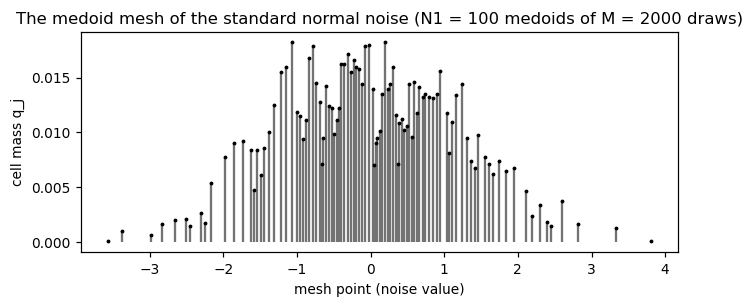

In [15]:
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.vlines(X1_g[:, 0], 0, mesh_g["q"], color="0.45"); ax.plot(X1_g[:, 0], mesh_g["q"], "k.", ms=3)
ax.set(title=f"The medoid mesh of the standard normal noise (N1 = {N1_g} medoids of M = {M_g} draws)",
       xlabel="mesh point (noise value)", ylabel="cell mass q_j"); plt.show()

The mesh is denser where $\nu$ has more mass, but less than proportionally.

## The three data-generating laws

The model asserts $Y\sim\mathcal N(\mu,\sigma^2)$. We keep $G$, the synthetic sample and the mesh
fixed and vary the law that produced the $n=5000$ observations.

| label | true observation law |
|---|---|
| `normal` | $\mathcal N(\mu_\star,\sigma_\star^2)$ — the model's own law |
| `t2` | $\mu_\star+\sigma_\star t_2$ — finite mean, infinite variance |
| `contam` | $5\%$ of the observations replaced by draws from $\mathcal N(\mu_\star+10\sigma_\star,\,0.5^2)$ |

The contamination is applied in observation space, before the split.

In [16]:
KINDS = ["normal", "t2", "contam"]
def draw_blocks(kind, rng):
    if kind == "normal":
        y = mu_star + sig_star * rng.standard_normal(n_g)
    elif kind == "t2":
        y = mu_star + sig_star * rng.standard_t(2, n_g)
    else:
        y = mu_star + sig_star * rng.standard_normal(n_g)
        bad = rng.choice(n_g, size=round(EPS * n_g), replace=False)
        y[bad] = rng.normal(mu_star + SHIFT * sig_star, SD_H, bad.size)
    y = rng.permutation(y)
    return {"y0": y[:n0_g].reshape(-1, 1), "y1": y[n0_g:n0_g + n1_g].reshape(-1, 1)}

rng = np.random.default_rng(37)
dat = {kd: draw_blocks(kd, rng) for kd in KINDS}
pd.DataFrame({kd: {"mean": d["y0"].mean(), "sd": d["y0"].std(ddof=1)} for kd, d in dat.items()}
             | {"P_theta0": {"mean": mu_star, "sd": sig_star}})

,normal,t2,contam,P_theta0
mean,0.6669,0.7837,1.1338,0.6838
sd,0.8929,3.2339,2.1230,0.8757


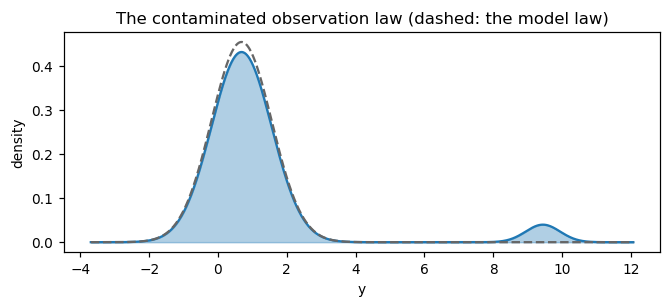

In [17]:
yy = np.linspace(mu_star - 5 * sig_star, mu_star + (SHIFT + 3) * sig_star, 900)
phi = lambda x, m, s: np.exp(-0.5 * ((x - m) / s) ** 2) / (s * math.sqrt(2 * math.pi))
dens = (1 - EPS) * phi(yy, mu_star, sig_star) + EPS * phi(yy, mu_star + SHIFT * sig_star, SD_H)
fig, ax = plt.subplots(figsize=(7, 2.6))
ax.fill_between(yy, dens, color="#1f78b4", alpha=0.35); ax.plot(yy, dens, color="#1f78b4")
ax.plot(yy, phi(yy, mu_star, sig_star), "--", color="0.4")
ax.set(title="The contaminated observation law (dashed: the model law)", xlabel="y", ylabel="density")
plt.show()

## Estimation stage (Algorithm 1)

A $25\times25$ grid over a data-driven box (median and MAD, since under $t_2$ a variance-scaled box
is seed-dependent), then Nelder–Mead in $(\mu,\log\sigma^2)$ from the three best grid points.

In [18]:
def make_grid_g(y0, res=25):
    y = np.ravel(y0); med = np.median(y); s = 1.4826 * np.median(np.abs(y - med))
    return expand_grid(np.linspace(med - 4 * s, med + 4 * s, res),
                       np.linspace(0.03, 3.0, res) * s ** 2)

def fit_g(y0, res=25, starts=3, Xs=Xs_g):
    return algorithm1(np.sort(np.ravel(y0)), Xs, G_gauss, make_grid_g(y0, res),
                      to_par_g, from_par_g, starts=starts)

fits = {kd: fit_g(d["y0"]) for kd, d in dat.items()}
pd.DataFrame({kd: {"mu": f["theta"][0], "sigma2": f["theta"][1], "F": f["value"],
                   "F_best_grid": f["Fval"].min()} for kd, f in fits.items()}).T

,mu,sigma2,F,F_best_grid
normal,0.6818,0.8135,0.0113,0.0282
t2,0.7169,1.6106,0.4069,0.4096
contam,0.7839,0.9053,0.3855,0.4107


The synthetic sample is itself random. Redrawing only the common random numbers, with the data
held fixed, shows how much $\tilde\theta$ moves for that reason; the spread should be small against
the sampling scale $\sigma_\star/\sqrt{n_0}$.

In [19]:
rng = np.random.default_rng(515)
crn = np.array([fit_g(dat["normal"]["y0"], res=13, starts=1,
                      Xs=np.sort(rng.standard_normal(m_g)).reshape(-1, 1))["theta"]
                for _ in range(reps(10, 3))])
pd.Series({"sd_mu_over_CRN": crn[:, 0].std(ddof=1), "sd_sigma2_over_CRN": crn[:, 1].std(ddof=1),
           "sampling_scale_mu": sig_star / math.sqrt(n0_g)})

sd_mu_over_CRN        0.0081
sd_sigma2_over_CRN    0.0157
sampling_scale_mu     0.0138
dtype: float64

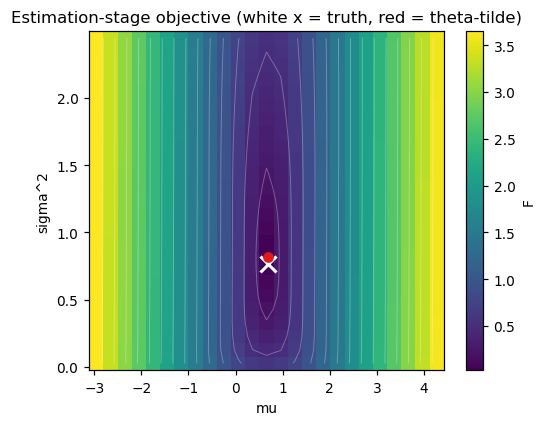

In [20]:
objective_plot(fits["normal"], (mu_star, s2_star),
               "Estimation-stage objective (white x = truth, red = theta-tilde)", "mu", "sigma^2")
plt.show()

## Is $\tilde\theta$ a typical draw from the prior? (Section 4.1)

The prior test uses only the estimation stage, so it comes before the recourse.

In [21]:
def prior_norm(A, B, Mu, K, rng, n=200000):
    s2 = 1.0 / rng.gamma(A, 1.0 / B, n)
    return np.sqrt((Mu + np.sqrt(s2 / K) * rng.standard_normal(n)) ** 2 + s2 ** 2)

th_hat = fits["normal"]["theta"]; t_obs = math.hypot(th_hat[0], th_hat[1])
cands = {"correct   (3, 2, 0, 1)": (3, 2, 0, 1), "m0 = 2    (3, 2, 2, 1)": (3, 2, 2, 1),
         "m0 = 5    (3, 2, 5, 1)": (3, 2, 5, 1), "scale     (10, 30, 0, 1)": (10, 30, 0, 1),
         "scale     (3, .5, 0, 1)": (3, 0.5, 0, 1), "kappa0=25 (3, 2, 0, 25)": (3, 2, 0, 25)}
rng = np.random.default_rng(99)
rows = []
for nm, h in cands.items():
    p = prior_p(t_obs, prior_norm(*h, rng))
    rows.append({"prior": nm, "E_sigma2": h[1] / (h[0] - 1), "p_value": p, "reject": p <= ALPHA})
pd.DataFrame(rows)

,prior,E_sigma2,p_value,reject
0,"correct (3, 2, 0, 1)",1.0000,0.9857,False
1,"m0 = 2 (3, 2, 2, 1)",1.0000,0.0866,False
2,"m0 = 5 (3, 2, 5, 1)",1.0000,0.0000,True
3,"scale (10, 30, 0, 1)",3.3333,0.0000,True
4,"scale (3, .5, 0, 1)",0.2500,0.1261,False
5,"kappa0=25 (3, 2, 0, 25)",1.0000,0.6062,False


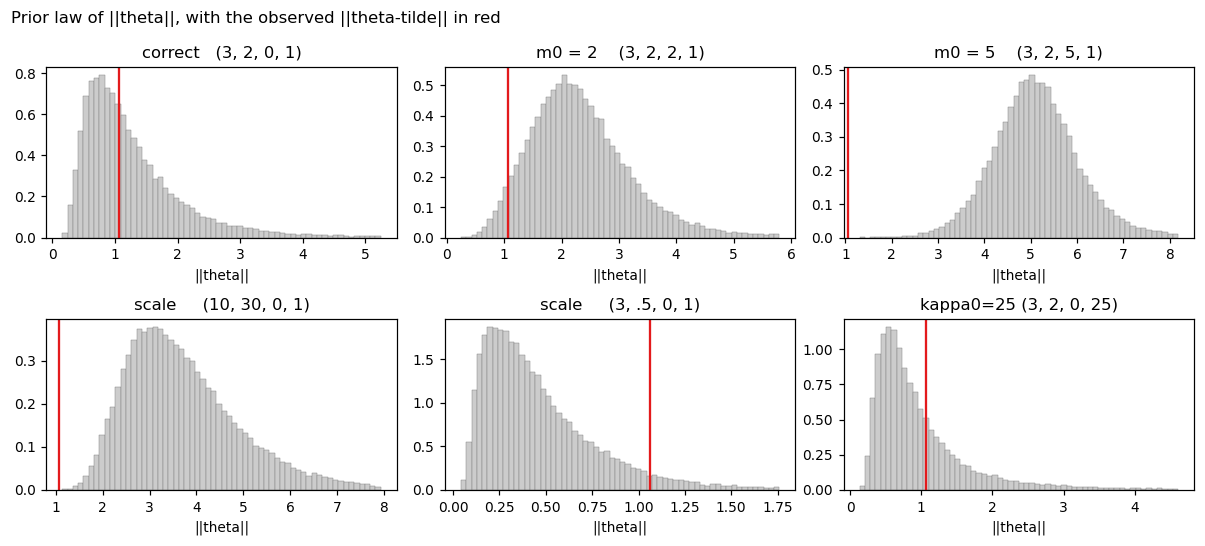

In [22]:
rng = np.random.default_rng(4)
fig, axes = plt.subplots(2, 3, figsize=(11, 5))
for ax, (nm, h) in zip(axes.ravel(), cands.items()):
    d = prior_norm(*h, rng, 40000); d = d[d < np.quantile(d, 0.99)]
    ax.hist(d, bins=60, density=True, color="0.8", edgecolor="0.5", lw=0.3)
    ax.axvline(t_obs, color=RED, lw=1.5); ax.set(title=nm, xlabel="||theta||")
fig.suptitle("Prior law of ||theta||, with the observed ||theta-tilde|| in red", x=0.01, ha="left")
fig.tight_layout(); plt.show()

The gross misspecifications (a shifted $m_0$, a rescaled inverse-gamma) should be rejected; the
$\kappa_0$ row is the instructive failure, since $\kappa_0$ changes only the prior spread of $\mu$, which
$\|\theta\|$ barely sees. Scoring fresh prior draws directly checks that the doubled $p$-value has the
nominal size.

In [23]:
rng = np.random.default_rng(123)
ref = np.sort(prior_norm(a0, b0, m0, k0, rng, 300000))
s2s = 1.0 / rng.gamma(a0, 1.0 / b0, 50000)
Fv = np.searchsorted(ref, np.sqrt((m0 + np.sqrt(s2s / k0) * rng.standard_normal(50000)) ** 2 + s2s ** 2),
                     side="right") / ref.size
p2 = np.minimum(1, 2 * np.minimum(Fv, 1 - Fv))
pd.Series({"size": np.mean(p2 <= ALPHA), "nominal": ALPHA})

size       0.05
nominal    0.05
dtype: float64

,mu,sigma2,norm,p_value
truth,0.6838,0.7669,1.0275,0.9447
normal,0.6818,0.8135,1.0615,0.9883
t2,0.7169,1.6106,1.7629,0.4114
contam,0.7839,0.9053,1.1975,0.8517


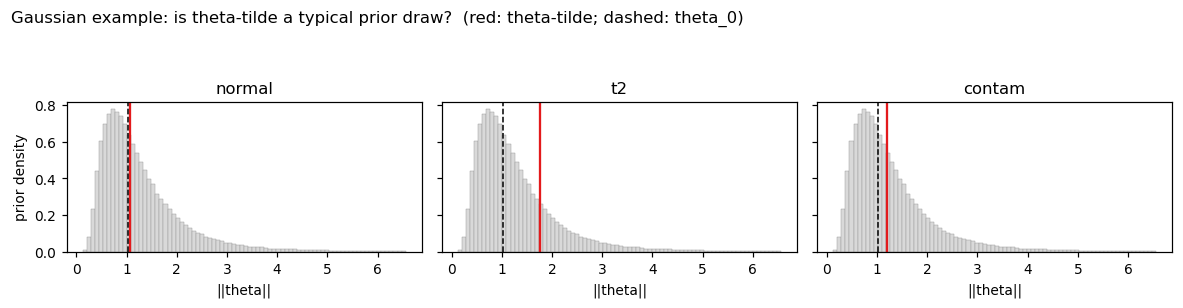

In [24]:
rng = np.random.default_rng(1009)
nn_correct = prior_norm(a0, b0, m0, k0, rng)
norm_g = lambda th: math.hypot(th[0], th[1])
PT_g = pd.DataFrame({"truth": {"mu": mu_star, "sigma2": s2_star, "norm": norm_g((mu_star, s2_star)),
                               "p_value": prior_p(norm_g((mu_star, s2_star)), nn_correct)}}
                    | {kd: {"mu": f["theta"][0], "sigma2": f["theta"][1], "norm": norm_g(f["theta"]),
                            "p_value": prior_p(norm_g(f["theta"]), nn_correct)} for kd, f in fits.items()}).T
display(PT_g)
prior_lines_plot(nn_correct, {kd: norm_g(f["theta"]) for kd, f in fits.items()}, norm_g((mu_star, s2_star)),
                 "Gaussian example: is theta-tilde a typical prior draw?", "||theta||")

The first row scores the true $\theta_0$ itself. The contamination and the heavy tails should distort
the noise diagnostic *without* making the structural parameter implausible under its prior; that is
the separation the split was built to produce.

## Recourse stage (Algorithm 3)

In [25]:
def wvor_g(theta):
    z = merge_atoms(G_gauss(theta, X1_g))[0][:, 0]
    return wvor_1d(z, lambda t: norm_cdf((t - theta[0]) / math.sqrt(theta[1])))

rec = {kd: algorithm3(dat[kd]["y1"], X1_g, fits[kd]["theta"], G_gauss) for kd in KINDS}
WV = {kd: wvor_g(fits[kd]["theta"]) for kd in KINDS}
pd.DataFrame({kd: {"L": rec[kd]["z"].shape[0], "Q": rec[kd]["Q"],
                   "min_expected_count": n1_g * WV[kd].min(),
                   "TV_from_wvor": 0.5 * np.abs(rec[kd]["w"] - WV[kd]).sum()} for kd in KINDS}).T

,L,Q,min_expected_count,TV_from_wvor
normal,100.0,0.0125,0.1787,0.1155
t2,100.0,0.0855,0.1787,0.1788
contam,100.0,0.2444,0.1787,0.1439


## The weight histogram

The mesh points are labelled in increasing order and $G(\tilde\theta,\cdot)$ is increasing, so the
display axis is the cell index, from the lowest atom to the highest. Because $G(\theta,\cdot)$ is
affine and increasing, the observation-space Voronoi cell of atom $\ell$ is the image of the noise
cell $C_\ell$, and $w^{\rm vor}_\ell(\theta)=\nu(C_\ell)$ for every $\theta$. The table counts the cells outside the pointwise interval
against the number expected under the model (below $\alpha N_1$, because the discreteness of the
binomial makes the interval conservative).

,outside,expected,cells
normal,4.0,3.0526,100.0
t2,15.0,3.0526,100.0
contam,7.0,3.0526,100.0


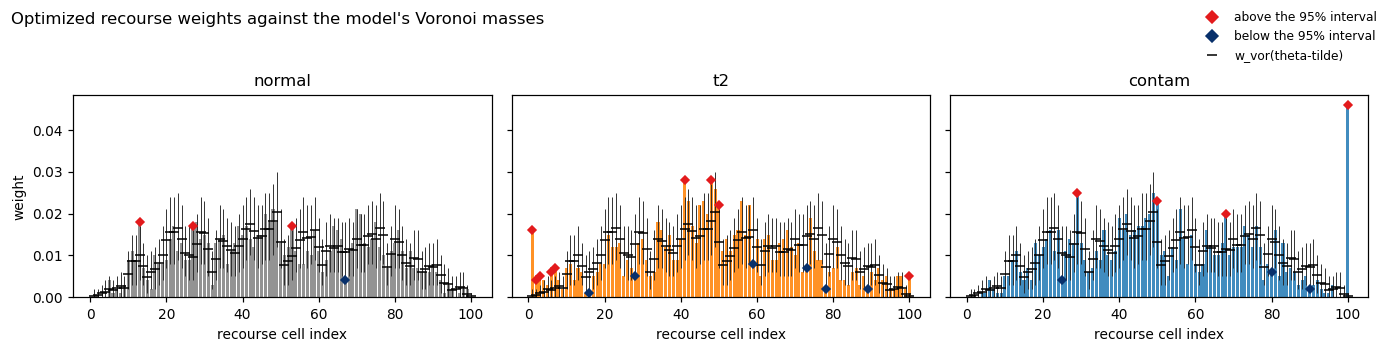

In [26]:
WH_g = pd.concat([weight_hist_df(rec[kd]["w"], WV[kd], n1_g, kd,
                                 np.argsort(np.argsort(rec[kd]["z"][:, 0])) + 1) for kd in KINDS])
OC_g = pd.DataFrame({kd: outside_count(WH_g[WH_g.case == kd], n1_g) for kd in KINDS}).T
display(OC_g)
weight_hist_plot(WH_g, KINDS, "Optimized recourse weights against the model's Voronoi masses",
                 "recourse cell index")

## The departure on a log scale

Dividing by $w^{\rm vor}(\tilde\theta)$ resolves the boundary behaviour, which is where the signal lives.
The grey band is a pointwise $95\%$ null envelope computed at each case's $\tilde\theta$; cells above it are
marked by a red cross (excess) and cells below it by a blue cross (deficit). Cells with no held-out
observation are drawn as open circles at the floor of the axis.

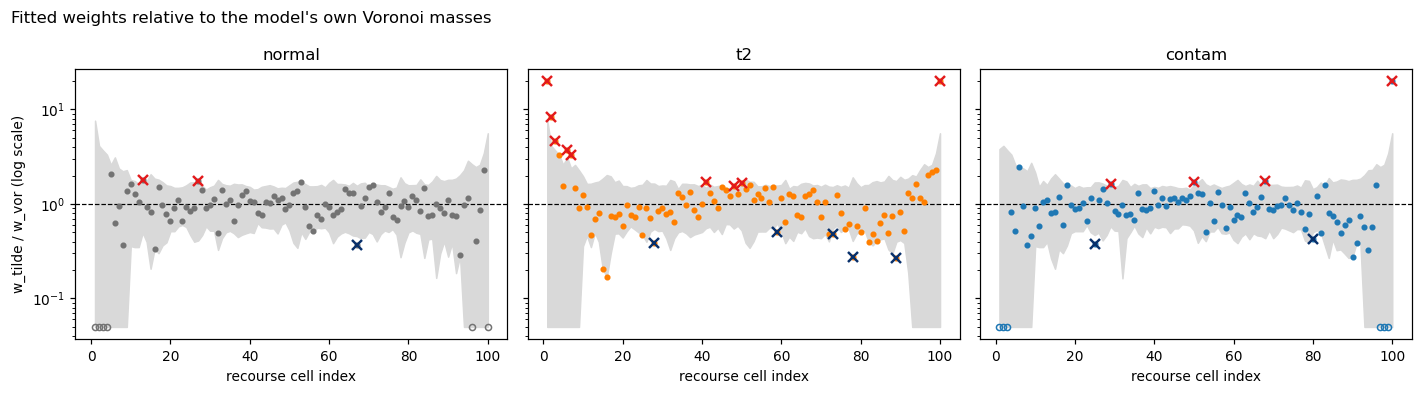

,cell_1,cell_N,expected_count_cell_1,expected_count_cell_N,excess_cells,deficit_cells
normal,0.0000,0.0000,0.2628,0.1787,2.0,1.0
t2,60.8901,27.9869,0.2628,0.1787,9.0,5.0
contam,0.0000,257.4799,0.2628,0.1787,4.0,2.0


In [27]:
rng = np.random.default_rng(7)
QB = {}
for kd in KINDS:
    th = fits[kd]["theta"]
    bw = np.array([algorithm3(th[0] + math.sqrt(th[1]) * rng.standard_normal(n1_g), X1_g, th,
                              G_gauss)["w"] for _ in range(reps(400, 50))])
    QB[kd] = np.quantile(bw / WV[kd], [0.025, 0.975], axis=0).T

FLOOR, CEIL = 0.05, 20
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, kd, col in zip(axes, KINDS, ["0.45", "#ff7f00", "#1f78b4"]):
    raw = rec[kd]["w"] / WV[kd]; ratio = np.clip(raw, FLOOR, CEIL); j = np.arange(1, N1_g + 1)
    ax.fill_between(j, np.clip(QB[kd][:, 0], FLOOR, CEIL), np.clip(QB[kd][:, 1], FLOOR, CEIL), color="0.85")
    ax.axhline(1, ls="--", color="k", lw=0.8)
    empty = rec[kd]["w"] == 0
    ax.plot(j[~empty], ratio[~empty], "o", color=col, ms=3)
    ax.plot(j[empty], ratio[empty], "o", mfc="none", color=col, ms=4)
    exc, dfc = raw > QB[kd][:, 1], raw < QB[kd][:, 0]
    ax.plot(j[exc], ratio[exc], "x", color=RED, ms=7, mew=1.6)
    ax.plot(j[dfc], ratio[dfc], "x", color=BLUE, ms=7, mew=1.6)
    ax.set(yscale="log", title=kd, xlabel="recourse cell index")
axes[0].set_ylabel("w_tilde / w_vor (log scale)")
fig.suptitle("Fitted weights relative to the model's own Voronoi masses", x=0.01, ha="left")
fig.tight_layout(); plt.show()

bd = pd.DataFrame({kd: {"cell_1": (rec[kd]["w"] / WV[kd])[0], "cell_N": (rec[kd]["w"] / WV[kd])[-1],
                        "expected_count_cell_1": n1_g * WV[kd][0], "expected_count_cell_N": n1_g * WV[kd][-1],
                        "excess_cells": int(np.sum((rec[kd]["w"] / WV[kd]) > QB[kd][:, 1])),
                        "deficit_cells": int(np.sum((rec[kd]["w"] / WV[kd]) < QB[kd][:, 0]))}
                   for kd in KINDS}).T
bd

The medoid mesh places its extreme points at extreme noise draws, so the two boundary cells have
small model mass and expected counts well below one; a single held-out point there gives a large ratio,
which is why the envelope is wide at the ends. Heavy tails ($t_2$) should load *both* boundary cells, the reading Section 4.2 gives for tails that
are too light in the model, with a deficit in the moderate cells in between. The contamination should be one-sided, at the top cell only, because
$G(\tilde\theta,\cdot)$ is increasing and every gross error is assigned to the top atom; that asymmetry is the
signature of an outlier group rather than of a symmetric tail defect.

## Compare with MLE

In [28]:
mle_of = lambda y0: (np.mean(y0), np.mean((y0 - np.mean(y0)) ** 2))
pd.DataFrame({kd: {"mu_W1": fits[kd]["theta"][0], "mu_MLE": mle_of(dat[kd]["y0"])[0],
                   "sigma_W1": math.sqrt(fits[kd]["theta"][1]), "sigma_MLE": math.sqrt(mle_of(dat[kd]["y0"])[1]),
                   "mu_star": mu_star, "sigma_star": sig_star} for kd in KINDS}).T

,mu_W1,mu_MLE,sigma_W1,sigma_MLE,mu_star,sigma_star
normal,0.6818,0.6669,0.9020,0.8928,0.6838,0.8757
t2,0.7169,0.7837,1.2691,3.2335,0.6838,0.8757
contam,0.7839,1.1338,0.9515,2.1227,0.6838,0.8757


## Gross-error contamination: minimum-$W_1$ against the MLE

In [29]:
err = lambda th: (abs(th[0] - mu_star), abs(math.sqrt(th[1]) - sig_star))
cmp = pd.DataFrame({"W1": err(fits["contam"]["theta"]), "MLE": err(mle_of(dat["contam"]["y0"]))},
                   index=["abs_error_mu", "abs_error_sigma"]).T
cmp.loc["ratio_MLE_over_W1"] = cmp.loc["MLE"] / cmp.loc["W1"]
cmp

,abs_error_mu,abs_error_sigma
W1,0.1001,0.0757
MLE,0.4500,1.2469
ratio_MLE_over_W1,4.4939,16.4658


$W_1$ against the empirical measure is an $L^1$ criterion, so a point moved to distance $R$ perturbs
the objective by only $O(R/n_0)$, whereas the sample variance is quadratic in the outlier distance:
$5\%$ of the data at $10\sigma_\star$ inflates $\hat\sigma_{\rm MLE}$ by roughly $\sqrt{1+0.05\cdot10^2}\approx2.4$.
This is qualitative robustness (Proposition 2), not a bounded influence function.

## The chi-squared test

In [30]:
pd.DataFrame({kd: chisq_recourse(rec[kd]["w"], WV[kd], n1_g, rec[kd]["z"]) for kd in KINDS}).T

,T,df,p
normal,81.4681,85.0,5.8839e-01
t2,301.2940,85.0,5.8065e-26
contam,262.0654,85.0,6.2079e-20


### Size and power

Each replicate runs the same two-stage pipeline — Algorithm 1, then Algorithm 3 — on fresh data,
with the common random numbers and the mesh held fixed. For cost, the replicate grid is $13\times13$
with a single Nelder–Mead start.

The size is estimated from $R_{\rm size}=400$ replicates under correct specification; its Monte Carlo
standard error is $\sqrt{\alpha(1-\alpha)/400}\approx0.011$, so an estimate within about $\pm0.022$ of
$0.05$ is consistent with exact calibration. The power against the two alternatives also uses $400$
replicates.

In [72]:
R_SIZE, R_POW = reps(400, 100), reps(400, 30)
R_by = {"normal": R_SIZE, "t2": R_POW, "contam": R_POW}
rng = np.random.default_rng(5)
t0 = time.time()
p_pow = {}
for kd in KINDS:
    ps = []
    for _ in range(R_by[kd]):
        d = draw_blocks(kd, rng)
        th = fit_g(d["y0"], res=13, starts=1)["theta"]
        r = algorithm3(d["y1"], X1_g, th, G_gauss)
        ps.append(chisq_recourse(r["w"], wvor_g(th), n1_g, r["z"])["p"])
    p_pow[kd] = np.array(ps)
nrep = {kd: int(np.sum(~np.isnan(p))) for kd, p in p_pow.items()}
pow_ = {kd: float(np.nanmean(p <= ALPHA)) for kd, p in p_pow.items()}
MCSE = {kd: math.sqrt(pow_[kd] * (1 - pow_[kd]) / nrep[kd]) for kd in KINDS}
CI = {kd: clopper_pearson(int(np.nansum(p_pow[kd] <= ALPHA)), nrep[kd]) for kd in KINDS}
print(f"elapsed: {time.time() - t0:.0f} s")
pd.DataFrame({kd: {"replicates": nrep[kd], "rejection_rate": pow_[kd], "monte_carlo_se": MCSE[kd],
                   "ci95_low": CI[kd][0], "ci95_high": CI[kd][1]} for kd in KINDS})

elapsed: 261 s


,normal,t2,contam
replicates,400.0000,400.0000,400.0000
rejection_rate,0.0400,1.0000,1.0000
monte_carlo_se,0.0098,0.0000,0.0000
ci95_low,0.0230,0.9908,0.9908
ci95_high,0.0641,1.0000,1.0000


A size estimate outside the band above is not replicate noise. The next cell separates its one
systematic source, the plug-in reference $w^{\rm vor}(\tilde\theta)$, from the test itself, by rerunning the
recourse with $\theta$ held at $\theta_0$, where the conditional multinomial theory is exact.

In [73]:
rng = np.random.default_rng(55); R_or = reps(2000, 200)
th_star = np.array([mu_star, s2_star]); wv_star = wvor_g(th_star)
p_or = np.array([chisq_recourse(algorithm3(mu_star + sig_star * rng.standard_normal(n1_g), X1_g, th_star,
                                           G_gauss)["w"], wv_star, n1_g, merge_atoms(G_gauss(th_star, X1_g))[0])["p"]
                 for _ in range(R_or)])
size_or = float(np.mean(p_or <= ALPHA))
pd.Series({"size_theta_at_truth": size_or, "mc_se": math.sqrt(size_or * (1 - size_or) / R_or),
           "size_full_pipeline": pow_["normal"], "mc_se_pipeline": MCSE["normal"], "nominal": ALPHA})

size_theta_at_truth    0.0530
mc_se                  0.0050
size_full_pipeline     0.0400
mc_se_pipeline         0.0098
nominal                0.0500
dtype: float64

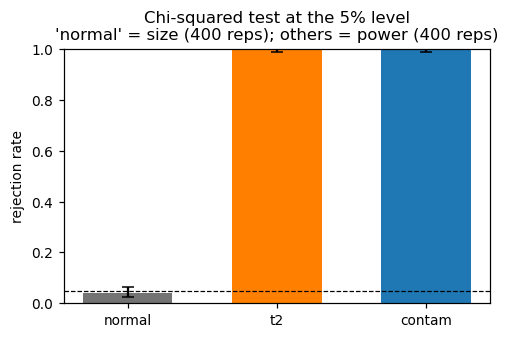

In [74]:
fig, ax = plt.subplots(figsize=(5, 3))
vals = [pow_[kd] for kd in KINDS]
ax.bar(KINDS, vals, color=["0.45", "#ff7f00", "#1f78b4"], width=0.6)
ax.errorbar(KINDS, vals, yerr=[[v - CI[kd][0] for v, kd in zip(vals, KINDS)],
                               [CI[kd][1] - v for v, kd in zip(vals, KINDS)]], fmt="none", color="k", capsize=4)
ax.axhline(ALPHA, ls="--", color="k", lw=0.8); ax.set_ylim(0, 1)
ax.set(title=f"Chi-squared test at the 5% level\n'normal' = size ({R_SIZE} reps); others = power ({R_POW} reps)",
       ylabel="rejection rate"); plt.show()

The `normal` bar is the size of the full pipeline; compare it with the size obtained with $\theta$ held
at the truth.

# Segregating sites under Kingman's coalescent

The history chapter of the *Handbook* (Tavaré, 2018) recalls the problem that started ABC. A sample of
$n$ sequences from one locus has a genealogy given by Kingman's coalescent (Kingman, 1982); mutations
fall on its branches as a Poisson process, so that, conditionally on the total branch length $L_n$, the
number of segregating sites is $S_n\mid L_n\sim\mathrm{Poisson}(\theta L_n/2)$. Watterson's estimator
$\theta_W=S_n/a_n$, $a_n=\sum_{j=1}^{n-1}1/j$, comes from $\mathbb E S_n=\theta a_n$ (Watterson, 1975). Here the
observations are the counts at independent, unlinked loci, so the data are i.i.d. and discrete while
the mechanism runs through a continuous, unobserved genealogy.

## Mechanism: a genealogy and a mutation clock

- **Genealogy.** Standard exponentials $E_2,\dots,E_n$ drive the coalescence times $T_k=E_k/\binom k2$,
  and $L_n=\sum_k kT_k=\sum_k 2E_k/(k-1)$.
- **Mutation clock.** A unit-rate Poisson process with arrival times $P_k$. By the random time change
  with a single channel, $G(\theta,x)=\#\{k:\ P_k\le\theta L_n/2\}$.

The mechanism depends on the genealogy only through $L_n$ (computed once per synthetic locus) and on
the clock only through its arrival times; each synthetic locus stores the first $K_{\max}$ arrivals,
enough for every $\theta\le\theta_{\rm cap}$.

**The recourse mesh.** The quantization metric is the Euclidean distance between two standardized
summaries of a noise draw: $\log L_n$ (genealogy length) and $\log R$, with $R=K/P_K$ the average rate
of the clock over its first $K=10$ arrivals (clock speed). A long genealogy with a slow clock and a
short genealogy with a fast clock give the same count, so in this plane the fibers are bands along
which $L_nR$ is roughly constant. The mesh points are full noise draws.

**The probability mass function is available** (Tavaré, 1984),
$P_\theta(S_n=s)=\sum_{i=1}^{n-1}(-1)^{i-1}\binom{n-1}{i}\frac{i}{\theta+i}\big(\frac{\theta}{\theta+i}\big)^s$, so the
Voronoi masses of the fitted constant-size model are exact.

## Parameters, prior, and the data-generating laws

We take $n=10$ sequences per locus and a lognormal prior on $\theta$ centred at $5$.

| label | true observation law |
|---|---|
| `correct` | the constant-size coalescent, $S_n\mid L_n\sim\mathrm{Poisson}(\theta_0L_n/2)$ |
| `growth` | exponential population growth at rate $g$ (Slatkin and Hudson, 1991): coalescence of $k$ lineages at rate $\binom k2e^{gt}$, which makes genealogies more star-like and their length less variable |

In [ ]:
N_SEQ = 10; a_n = sum(1.0 / j for j in range(1, N_SEQ))
n0_C, n1_C, m_C = 4000, 1000, 10000
N1_C, M_C = 300, 2500
K_RATE, TH_CAP, GR_C = 10, 25.0, 0.7

def tree_len(m, rng, g=0.0, n=N_SEQ):
    L = np.zeros(m); t = np.zeros(m)
    for k in range(n, 1, -1):
        r = k * (k - 1) / 2; E = rng.exponential(size=m)
        Tk = E / r if g == 0 else np.log1p(g * np.exp(-g * t) * E / r) / g
        t += Tk; L += k * Tk
    return L

def clock_arrivals(m, K, rng):
    return np.cumsum(rng.exponential(size=(m, K)), axis=1)

theta0_rng = np.random.default_rng(134)
th0_C = float(theta0_rng.lognormal(math.log(5), 0.5))
rng = np.random.default_rng(135)
L_C = tree_len(m_C, rng)
lam_max = TH_CAP * L_C.max() / 2
KMAX_C = int(lam_max + 8 * math.sqrt(lam_max) + 20)          # far above any count needed
Xs_C = {"L": L_C, "P": clock_arrivals(m_C, KMAX_C, rng)}
sub_noise = lambda X, i: {"L": X["L"][i], "P": X["P"][i]}

def G_seg(theta, X):
    tt = theta[0] * X["L"] / 2
    if np.any(X["P"][:, -1] <= tt):
        return None                                           # the clock ran out
    k = int(min(X["P"].shape[1], tt.max() + 8 * math.sqrt(tt.max() + 1) + 20))
    if k < X["P"].shape[1] and np.any(X["P"][:, k - 1] <= tt):
        k = X["P"].shape[1]
    return (X["P"][:, :k] <= tt[:, None]).sum(axis=1).astype(float).reshape(-1, 1)

feat_C = np.column_stack([np.log(Xs_C["L"]), np.log(K_RATE / Xs_C["P"][:, K_RATE - 1])])
feat_C = (feat_C - feat_C.mean(0)) / feat_C.std(0, ddof=1)
mesh_C = algorithm2(feat_C, N1_C, M_C, np.random.default_rng(136))
X1_C = sub_noise(Xs_C, mesh_C["idx"])

def pmf_S(s, th, n=N_SEQ):
    s = np.atleast_1d(np.asarray(s, dtype=float)); i = np.arange(1, n)
    c = np.array([math.comb(n - 1, int(v)) for v in i]) * (-1.0) ** (i - 1) * i / (th + i)
    out = (c[None, :] * (th / (th + i))[None, :] ** np.maximum(s, 0)[:, None]).sum(1)
    return np.where(s < 0, 0.0, np.maximum(out, 0.0))

def cdf_S(t, th, n=N_SEQ):
    f = np.floor(np.asarray(t, dtype=float) + 1e-9); mx = int(max(0, f.max()))
    cum = np.cumsum(pmf_S(np.arange(mx + 1), th, n))
    return np.where(f < 0, 0.0, np.minimum(cum[np.clip(f, 0, mx).astype(int)], 1.0))

def gen_C(kind, n, rng):
    if kind == "correct":
        return rng.poisson(th0_C * tree_len(n, rng) / 2).astype(float)
    if kind == "growth":
        return rng.poisson(th0_C * tree_len(n, rng, g=GR_C) / 2).astype(float)
    raise ValueError(kind)

def grid_C(y0):
    tw = np.mean(y0) / a_n
    return np.linspace(0.25 * tw, min(3 * tw + 0.5, TH_CAP), 41).reshape(-1, 1)

def fit_C(y0, y1, starts=3):
    return lattice_fit_recourse(y0, y1, G_seg, Xs_C, grid_C(y0), X1_C, cdf_S, pmf_S, starts=starts)

pd.Series({"theta0": th0_C, "n_sequences": N_SEQ, "a_n": a_n, "n0": n0_C, "n1": n1_C, "m": m_C,
           "K_max": KMAX_C, "M": M_C, "N1": N1_C, "mean_S": th0_C * a_n})

## Estimation

In [ ]:
KINDS_C = ["correct", "growth"]
rng = np.random.default_rng(51)
dat_C = {kd: {"y0": gen_C(kd, n0_C, rng), "y1": gen_C(kd, n1_C, rng)} for kd in KINDS_C}
fits_C = {kd: fit_C(d["y0"], d["y1"]) for kd, d in dat_C.items()}
pd.DataFrame({kd: {"theta_W1": f["theta"][0], "theta_Watterson": dat_C[kd]["y0"].mean() / a_n}
              for kd, f in fits_C.items()}).T

## Is $\tilde\theta$ a typical draw from the prior?

In [ ]:
prior_C = np.random.default_rng(717).lognormal(math.log(5), 0.5, 200000)
PT_C = pd.DataFrame({"truth": {"theta": th0_C, "p_value": prior_p(th0_C, prior_C)}}
                    | {kd: {"theta": f["theta"][0], "p_value": prior_p(f["theta"][0], prior_C)}
                       for kd, f in fits_C.items()}).T
display(PT_C)
prior_lines_plot(prior_C, {kd: f["theta"][0] for kd, f in fits_C.items()}, th0_C,
                 "Segregating sites: is theta-tilde a typical prior draw?", "theta")

## Recourse

The test on the held-out block, with the number of merged atoms $L$:

In [ ]:
pd.DataFrame({kd: {"L": f["z"].shape[0], **f["test"]} for kd, f in fits_C.items()}).T

The mesh points collapse onto a few dozen merged atoms: each atom is a count, and its fiber is the set
of noise draws — genealogy and clock — that produce it.

In [ ]:
WH_C = pd.concat([weight_hist_df(f["w"], f["wv"], n1_C, kd, f["z"][:, 0]) for kd, f in fits_C.items()])
weight_hist_plot(WH_C, KINDS_C, "Segregating sites: recourse weights on the merged atoms",
                 "segregating sites S (merged atom)")
SG_C = pd.DataFrame({kd: signature_lattice(f) for kd, f in fits_C.items()}).T
SG_C

Exponential growth makes genealogies longer and less variable than under the constant-size
coalescent.

## What the noise plane can and cannot show

Remark 1 says the held-out data identify the noise law only up to the fibers of the fitted mechanism.
Each mesh point is drawn at its genealogy length $L_n$ and clock rate $R$ and coloured by the ratio of
the count it produces under $\tilde\theta$; the fibers are the bands of equal colour along $L_nR\approx$
constant.

In [ ]:
NS_C = {}
for kd, f in fits_C.items():
    d = lift_to_mesh(f, f["wv"], n1_C, mesh_C["q"])
    d["v1"] = X1_C["L"]; d["v2"] = K_RATE / X1_C["P"][:, K_RATE - 1]
    NS_C[kd] = d
noise_plane_plot(NS_C, KINDS_C, "Segregating sites: the recourse on the noise mesh (Remark 1)",
                 "genealogy length L_n (log scale)", "mutation-clock rate R (log scale)")

# The Yule (pure birth) process: a simulation example

## Mechanism: thinning a Poisson random measure

A population starts from $z_0$ individuals and each individual gives birth at rate $\lambda$; there are no
deaths. This is the Yule process, the pure-birth case of the linear birth–death process (Kendall, 1948).
Each replicate (independent culture wells, say) is recorded at $t=1,2,3,4$, so
$Y=(Z(1),\dots,Z(4))\in\mathbb R^4$ and $\theta=\lambda$ is one-dimensional. Following eq. (7) and Example 3 with a
single reaction channel,
$$Z(t)=z_0+\int_0^t\!\!\int_0^\infty\mathbf 1\{u\le\lambda Z(s-)\}\,N(ds,du),$$
with $N$ a Poisson random measure of intensity $ds\,du$ (Fournier and Méléard, 2004). The noise is the
Poisson sample path $N$, a point configuration: an atom $(s,u)$ is a candidate birth at time $s$, accepted
when $u\le\lambda Z(s-)$. The jump times are atom times and do not move with $\lambda$; a change of $\lambda$ only
changes which candidates are accepted.

**Simulating the noise.** The configuration is simulated on the window $[0,T]\times[0,\bar u]$: a
Poisson $(T\bar u)$ number of atoms with uniform times and heights. `make_prm` stores, per replicate, the
atom times in increasing order and their heights, padded with `inf`; `yule_prm` visits the atoms in time
order for all replicates at once. The window is exact as long as $\lambda Z$ stays below $\bar u$; otherwise the
mechanism returns `None` and the search treats $\lambda$ as infeasible. The data are generated by Gillespie's
direct method (Gillespie, 1977), which uses different random numbers.

**The recourse mesh.** As in Example 3, $d_Q$ is the Euclidean distance between the atom counts of two
configurations on a grid of rectangles: $8$ time bins of width $0.5$ times $5$ height bins with edges
$0,2,4,8,16,32$ (a $40$-dimensional count vector). The observations are integer vectors, so condition
(5b) holds and ties are detected exactly. The model's Voronoi masses are the cell frequencies of $40{,}000$
paths simulated from the fitted model.

**Misspecification: a state-dependent birth rate.** In `saturating` the per-capita birth rate falls as the
population grows,
$$\lambda(z)=\lambda_0\,\frac{K}{K+z}$$
and K=`K_SAT`, so the total birth rate $\lambda_0Kz/(K+z)$ saturates at $\lambda_0K$: growth is close to exponential while
$z\ll K$ and close to linear in time once $z\gg K$. A Yule process has a constant per-capita rate. It can
match the average growth over the four time points with a single $\lambda$, but then it grows too slowly at
the start and too fast at the end.

| label | true observation law |
|---|---|
| `correct` | Yule process with rate $\lambda_0$ |
| `saturating` | per-capita birth rate $\lambda_0K/(K+z)$ |

In [32]:
Z0_B, TT_B = 5, np.array([1.0, 2.0, 3.0, 4.0]); J_B = TT_B.size
n0_B, n1_B, m_B = 4000, 1000, 2000
UBAR_B, N1_B, M_B, B_WV, K_SAT = 150.0, 150, 1500, 40000, 10.0

def make_prm(m, rng, T=TT_B[-1], ub=UBAR_B):
    N = rng.poisson(T * ub, m); K = N.max()
    S = rng.uniform(0, T, (m, K))
    S[np.arange(K)[None, :] >= N[:, None]] = np.inf
    S.sort(axis=1)                                     # time order; padding last
    return {"S": S, "U": rng.uniform(0, ub, (m, K))}
sub_prm = lambda X, i: {k: v[i] for k, v in X.items()}

def yule_prm(theta, X, z0=Z0_B, tt=TT_B, ub=UBAR_B):
    """Thinning mechanism of eq. (7): the atom (s, u) is a birth if u <= lambda * Z(s-)."""
    lam = float(theta[0])
    S, U = X["S"], X["U"]; m = S.shape[0]
    Y = np.full((m, tt.size), np.nan); z = np.full(m, float(z0))
    last = int(np.isfinite(S).sum(axis=1).max())
    for k in range(last):
        s = S[:, k]
        for j in range(tt.size):                       # record the state at the times passed
            rec = np.isnan(Y[:, j]) & (s > tt[j])
            Y[rec, j] = z[rec]
        z = z + (np.isfinite(s) & (U[:, k] <= lam * z))
    for j in range(tt.size):
        rec = np.isnan(Y[:, j]); Y[rec, j] = z[rec]
    if lam * z.max() > ub:
        return None                                    # the window is too low
    return Y

def prm_features(X, tb=np.arange(0, TT_B[-1] + 0.5, 0.5), ubk=np.array([0, 2, 4, 8, 16, 32.0])):
    S, U = X["S"], X["U"]; m = S.shape[0]
    nt, nu = tb.size - 1, ubk.size - 1; nc = nt * nu
    ok = np.isfinite(S) & (U < ubk[-1])
    ti = np.clip(np.searchsorted(tb, S[ok], side="right") - 1, 0, nt - 1)
    ui = np.searchsorted(ubk, U[ok], side="right") - 1
    rowi = np.nonzero(ok)[0]
    return np.bincount(rowi * nc + ti * nu + ui, minlength=m * nc).reshape(m, nc).astype(float)

def birth_gillespie(n, birth, rng, z0=Z0_B, tt=TT_B):
    """Gillespie's direct method for a pure birth process with total birth rate birth(z)."""
    Y = np.full((n, tt.size), np.nan); z = np.full(n, float(z0)); t = np.zeros(n)
    act = np.ones(n, dtype=bool)
    while act.any():
        r = np.flatnonzero(act)
        tn = t[r] + rng.exponential(size=r.size) / birth(z[r])
        for j in range(tt.size):
            rec = np.isnan(Y[r, j]) & (tn > tt[j]); Y[r[rec], j] = z[r[rec]]
        z[r] += 1.0; t[r] = tn
        act[r] = np.isnan(Y[r, -1])
    return Y

lam0_B = float(np.random.default_rng(2401).lognormal(math.log(0.5), 0.15))   # theta_0, a prior draw
th0_B = np.array([lam0_B])
Xs_B = make_prm(m_B, np.random.default_rng(2402))      # synthetic noise configurations
mesh_B = algorithm2(prm_features(Xs_B), N1_B, M_B, np.random.default_rng(2403))
X1_B = sub_prm(Xs_B, mesh_B["idx"])
DIRS_B = make_dirs(J_B, np.random.default_rng(2404))
w1_B = lambda y, z: sliced_w1(y, z, DIRS_B)

def gen_B(kind, n, rng):
    if kind == "correct":
        return birth_gillespie(n, lambda z: lam0_B * z, rng)
    if kind == "saturating":
        return birth_gillespie(n, lambda z: lam0_B * K_SAT * z / (K_SAT + z), rng)
    raise ValueError(kind)

def grid_B(y0, res=41):
    lam_s = math.log(max(y0[:, -1].mean(), Z0_B + 1e-3) / Z0_B) / TT_B[-1]   # E Z(T) = z0 e^{lambda T}
    return np.linspace(0.4 * lam_s, 2 * lam_s, res).reshape(-1, 1)

def growth_features(Y):
    """Early and late log-growth of count trajectories."""
    return np.log(Y[:, 0] / Z0_B), np.log(Y[:, -1] / Y[:, 1]) / (TT_B[-1] - TT_B[1])

def fit_B(y0, y1, rng, starts=3):
    a1 = algorithm1(y0, Xs_B, yule_prm, grid_B(y0), starts=starts, w1=w1_B)
    th = a1["theta"]
    r = algorithm3(y1, X1_B, th, yule_prm)
    Ysim = birth_gillespie(B_WV, lambda z: th[0] * z, rng)
    wv = wvor_sim(r["z"], Ysim)
    ge, gl = growth_features(Ysim)
    r.update(theta=th, wv=wv, fit=a1, Ysim_q=np.quantile(Ysim, [0.05, 0.25, 0.5, 0.75, 0.95], axis=0),
             q_early=np.quantile(ge, [0.2, 0.8]), q_late=np.quantile(gl, [0.2, 0.8]),
             test=chisq_recourse(r["w"], wv, y1.shape[0], r["z"]))
    return r

pd.Series({"lambda0": lam0_B, "z0": Z0_B, "n0": n0_B, "n1": n1_B, "m": m_B,
           "max_atoms_per_replicate": Xs_B["S"].shape[1], "M": M_B, "N1": N1_B, "K_sat": K_SAT,
           "mean_Z(4)": Z0_B * math.exp(lam0_B * 4)})

lambda0                       0.5759
z0                            5.0000
n0                         4000.0000
n1                         1000.0000
m                          2000.0000
max_atoms_per_replicate     679.0000
M                          1500.0000
N1                          150.0000
K_sat                        10.0000
mean_Z(4)                    50.0430
dtype: float64

## Estimation

In [33]:
KINDS_B = ["correct", "saturating"]
rng = np.random.default_rng(2411)
dat_B = {}
for kd in KINDS_B:
    y = gen_B(kd, n0_B + n1_B, rng); dat_B[kd] = {"y0": y[:n0_B], "y1": y[n0_B:]}
rng = np.random.default_rng(2412)
fits_B = {kd: fit_B(d["y0"], d["y1"], rng) for kd, d in dat_B.items()}
pd.DataFrame({kd: {"lambda": f["theta"][0]} for kd, f in fits_B.items()}).T

,lambda
correct,0.5713
saturating,0.2969


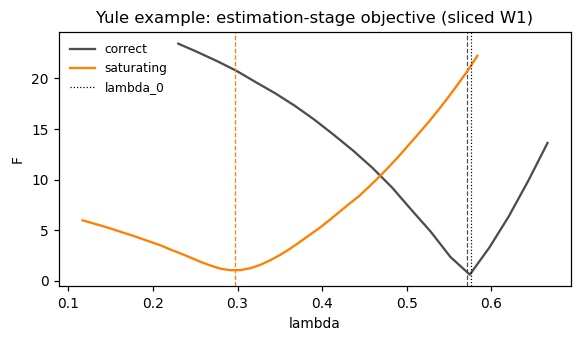

In [34]:
fig, ax = plt.subplots(figsize=(6, 3))
for kd, col in zip(KINDS_B, ["0.3", "#ff7f00"]):
    g, F = fits_B[kd]["fit"]["grid"][:, 0], fits_B[kd]["fit"]["Fval"].copy(); F[~np.isfinite(F)] = np.nan
    ax.plot(g, F, color=col, label=kd); ax.axvline(fits_B[kd]["theta"][0], color=col, ls="--", lw=0.8)
ax.axvline(lam0_B, color="k", lw=0.8, ls=":", label="lambda_0")
ax.set(title="Yule example: estimation-stage objective (sliced W1)", xlabel="lambda", ylabel="F")
ax.legend(frameon=False, fontsize=8); plt.show()

## Is $\tilde\theta$ a typical draw from the prior?

The prior is $\lambda\sim\mathrm{LogNormal}(\log0.5,0.15^2)$; the statistic is $\lambda$ itself.

,lambda,p_value
truth,0.5759,0.3433
correct,0.5713,0.3710
saturating,0.2969,0.0005


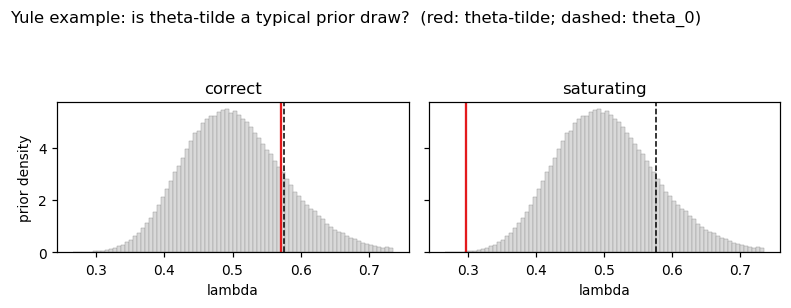

In [35]:
prior_B = np.random.default_rng(2421).lognormal(math.log(0.5), 0.15, 200000)
PT_B = pd.DataFrame({"truth": {"lambda": lam0_B, "p_value": prior_p(lam0_B, prior_B)}}
                    | {kd: {"lambda": f["theta"][0], "p_value": prior_p(f["theta"][0], prior_B)}
                       for kd, f in fits_B.items()}).T
display(PT_B)
prior_lines_plot(prior_B, {kd: f["theta"][0] for kd, f in fits_B.items()}, lam0_B,
                 "Yule example: is theta-tilde a typical prior draw?", "lambda")

## Recourse

The test on the held-out block, with the number of merged atoms:

In [36]:
pd.DataFrame({kd: {"atoms": f["z"].shape[0], **f["test"]} for kd, f in fits_B.items()}).T

,atoms,T,df,p
correct,149.0,107.3769,102.0,3.3851e-01
saturating,135.0,483.9384,92.0,1.5645e-54


The weight histogram orders the merged count vectors by the final count $Z(4)$, then by the earlier
counts.

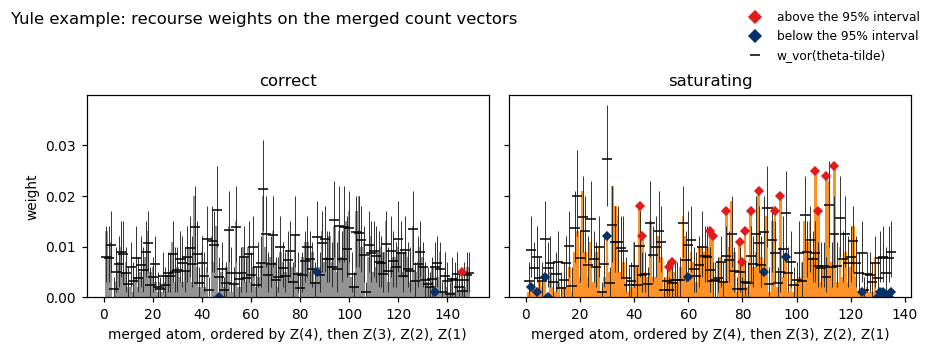

,outside,expected,early_slow,early_fast,late_slow,late_fast
correct,4.0,4.2011,0.9501,1.0531,0.8696,0.9848
saturating,33.0,3.8683,0.5758,1.4343,1.2146,0.5283


In [37]:
def atom_order_x(z):
    o = np.lexsort(z.T)                     # last column is the primary key
    x = np.empty(z.shape[0], dtype=int); x[o] = np.arange(1, z.shape[0] + 1); return x
WH_B = pd.concat([weight_hist_df(f["w"], f["wv"], n1_B, kd, atom_order_x(f["z"])) for kd, f in fits_B.items()])
OC_B = pd.DataFrame({kd: outside_count(WH_B[WH_B.case == kd], n1_B) for kd in KINDS_B}).T
weight_hist_plot(WH_B, KINDS_B, "Yule example: recourse weights on the merged count vectors",
                 "merged atom, ordered by Z(4), then Z(3), Z(2), Z(1)", width=1.0)

def bd_groups(f):
    ge, gl = growth_features(f["z"])
    return {"early_slow": ge <= f["q_early"][0], "early_fast": ge >= f["q_early"][1],
            "late_slow": gl <= f["q_late"][0], "late_fast": gl >= f["q_late"][1]}
SG_B = pd.DataFrame({kd: {"outside": OC_B.loc[kd, "outside"], "expected": OC_B.loc[kd, "expected"],
                          **{g: group_ratio(f, s) for g, s in bd_groups(f).items()}}
                     for kd, f in fits_B.items()}).T
SG_B

The last four columns pool the atoms by two features of their trajectory, relative to the fitted model's
own law: the early growth $\log(Z(1)/z_0)$ and the late growth $\log(Z(4)/Z(2))/2$ (the slowest and the
fastest fifth of each), and give the ratio of held-out weight to model mass in each group; under the model
all are near $1$. A saturating birth rate should show as an excess of trajectories that grow fast early and
slowly late, and a deficit of the reverse.

## The data against the fitted model over time

The shaded bands are the $5$–$95\%$ and $25$–$75\%$ quantiles of $Z(t)$ under the fitted Yule model, the black
line the median, and the red lines the same quantiles of the held-out data.

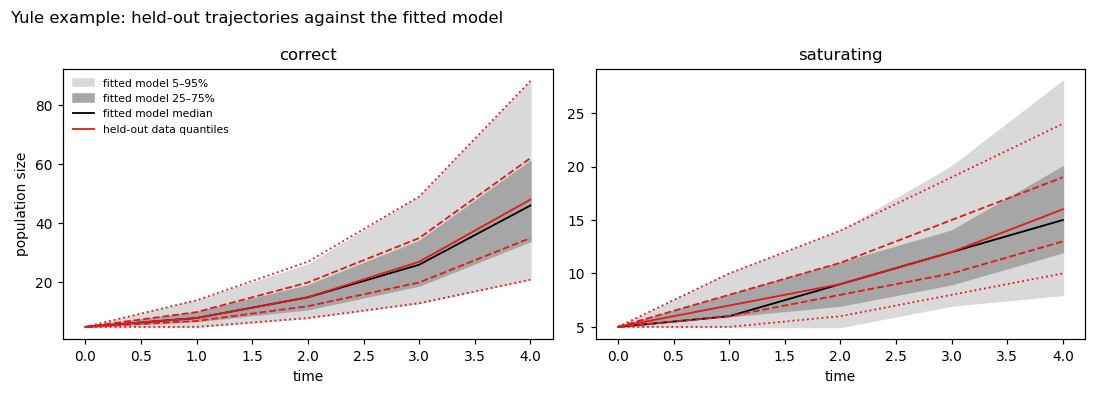

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
tgrid = np.concatenate([[0], TT_B])
for ax, kd in zip(axes, KINDS_B):
    f = fits_B[kd]; Q = np.column_stack([np.full(5, Z0_B), f["Ysim_q"]])
    Qd = np.column_stack([np.full(5, Z0_B), np.quantile(dat_B[kd]["y1"], [0.05, 0.25, 0.5, 0.75, 0.95], axis=0)])
    ax.fill_between(tgrid, Q[0], Q[4], color="0.85", label="fitted model 5–95%")
    ax.fill_between(tgrid, Q[1], Q[3], color="0.65", label="fitted model 25–75%")
    ax.plot(tgrid, Q[2], color="k", lw=1.2, label="fitted model median")
    for k, ls in zip(range(5), [":", "--", "-", "--", ":"]):
        ax.plot(tgrid, Qd[k], color=RED, ls=ls, lw=1.2, label="held-out data quantiles" if k == 2 else None)
    ax.set(title=kd, xlabel="time")
axes[0].set_ylabel("population size"); axes[0].legend(fontsize=7, frameon=False, loc="upper left")
fig.suptitle("Yule example: held-out trajectories against the fitted model", x=0.01, ha="left")
fig.tight_layout(); plt.show()

## The diagnostic as trajectories

Each atom is a trajectory of counts, so the flagged cells are drawn as trajectories, excess (red, top) and
deficit (blue, bottom) separately; grey atoms are inside the pointwise $95\%$ interval.

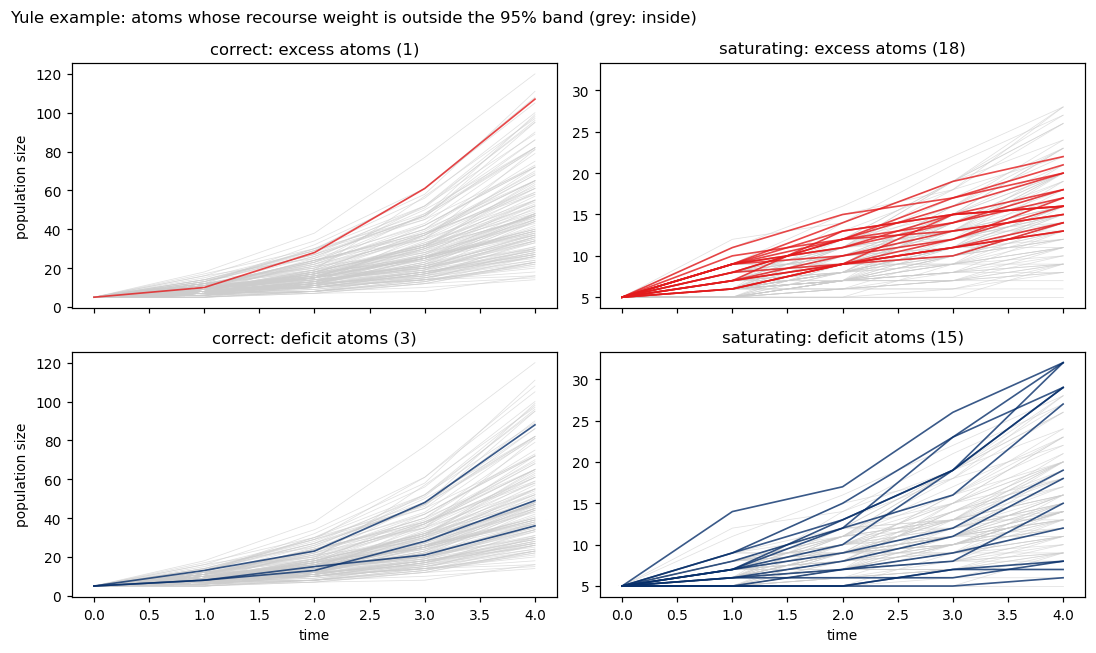

In [39]:
fig, axes = plt.subplots(2, 2, figsize=(10, 6), sharex=True, sharey="col")
for c, kd in enumerate(KINDS_B):
    f = fits_B[kd]
    lo, hi = binom_ppf(ALPHA / 2, n1_B, f["wv"]) / n1_B, binom_ppf(1 - ALPHA / 2, n1_B, f["wv"]) / n1_B
    flag = direction(f["w"], lo, hi)
    paths = np.column_stack([np.full(f["z"].shape[0], Z0_B), f["z"]])
    for r, (lab, col) in enumerate((("excess", RED), ("deficit", BLUE))):
        ax = axes[r, c]
        for l in np.flatnonzero(flag == "inside"):
            ax.plot(tgrid, paths[l], color="0.8", lw=0.5, alpha=0.6)
        for l in np.flatnonzero(flag == lab):
            ax.plot(tgrid, paths[l], color=col, lw=1.1, alpha=0.8)
        ax.set_title(f"{kd}: {lab} atoms ({int(np.sum(flag == lab))})")
        if r == 1: ax.set_xlabel("time")
    axes[0, 0].set_ylabel("population size"); axes[1, 0].set_ylabel("population size")
fig.suptitle("Yule example: atoms whose recourse weight is outside the 95% band (grey: inside)",
             x=0.01, ha="left"); fig.tight_layout(); plt.show()

## The diagnostic in observation and noise space

The top row shows,
in observation space, the atoms whose recourse weight falls outside its pointwise $95\%$ band (red:
excess, blue: deficit), the other atoms in grey, and the held-out trajectories counted into the excess
cells as thin red lines. The bottom row shows the noise behind them: the mesh points are sample paths of
the Poisson random measure $N$, and each is drawn as the counting process
$$N_{\tilde\lambda}(t)=\#\big\{(s,u)\in N:\ s\le t,\ u\le\tilde\lambda\,z_0e^{\tilde\lambda s}\big\},$$
the number of atoms below the acceptance level of the fitted model along its mean path
$z_0e^{\tilde\lambda s}$. Under the noise law $N_{\tilde\lambda}$ is a Poisson process with mean
$z_0(e^{\tilde\lambda t}-1)$ (dashed). Every mesh point of a flagged fiber is coloured like its atom.

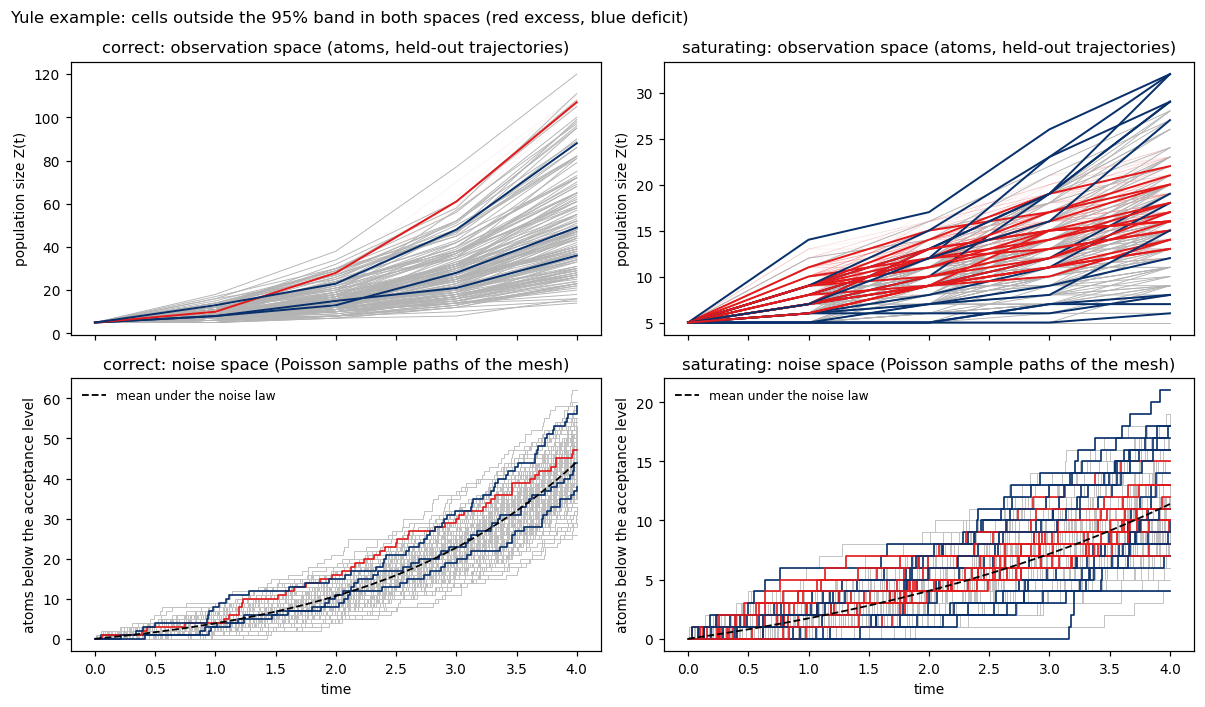

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
tgrid = np.concatenate([[0], TT_B]); tfine = np.linspace(0, TT_B[-1], 401)
for c, kd in enumerate(KINDS_B):
    f = fits_B[kd]; lam = float(f["theta"][0])
    lo, hi = binom_ppf(ALPHA / 2, n1_B, f["wv"]) / n1_B, binom_ppf(1 - ALPHA / 2, n1_B, f["wv"]) / n1_B
    flag = direction(f["w"], lo, hi)                 # one flag per atom
    mflag = flag[f["fiber"]]                         # the flag of each mesh point's fiber
    paths = np.column_stack([np.full(f["z"].shape[0], Z0_B), f["z"]])
    ax_o, ax_n = axes[0, c], axes[1, c]
    # observation space: held-out trajectories in excess cells, then atoms
    for i in np.flatnonzero(flag[f["cell"]] == "excess"):
        ax_o.plot(tgrid, np.concatenate([[Z0_B], dat_B[kd]["y1"][i]]), color=RED, alpha=0.08, lw=0.4)
    for l in np.flatnonzero(flag == "inside"):
        ax_o.plot(tgrid, paths[l], color="0.7", lw=0.6)
    for l in np.flatnonzero(flag != "inside"):
        ax_o.plot(tgrid, paths[l], color=RED if flag[l] == "excess" else BLUE, lw=1.3)
    # noise space: counting process of the atoms below the fitted acceptance level
    S, U = X1_B["S"], X1_B["U"]
    for pass_ in ("inside", "flagged"):
        for j in range(S.shape[0]):
            if (mflag[j] == "inside") != (pass_ == "inside"):
                continue
            ok = np.isfinite(S[j]) & (U[j] <= lam * Z0_B * np.exp(lam * np.where(np.isfinite(S[j]), S[j], 0.0)))
            Nt = np.searchsorted(np.sort(S[j][ok]), tfine, side="right")
            col = "0.75" if mflag[j] == "inside" else (RED if mflag[j] == "excess" else BLUE)
            ax_n.step(tfine, Nt, where="post", color=col, lw=0.6 if mflag[j] == "inside" else 1.1)
    ax_n.plot(tfine, Z0_B * np.expm1(lam * tfine), "k--", lw=1.2, label="mean under the noise law")
    ax_o.set_title(f"{kd}: observation space (atoms, held-out trajectories)")
    ax_n.set_title(f"{kd}: noise space (Poisson sample paths of the mesh)")
    ax_o.set_ylabel("population size Z(t)"); ax_n.set_ylabel("atoms below the acceptance level")
    ax_n.set_xlabel("time"); ax_n.legend(frameon=False, fontsize=8, loc="upper left")
fig.suptitle("Yule example: cells outside the 95% band in both spaces (red excess, blue deficit)",
             x=0.01, ha="left")
fig.tight_layout(); plt.show()

# The Ornstein–Uhlenbeck diffusion: a simulation example

## Mechanism, noise and mesh

Example 4 of the manuscript is the Ornstein–Uhlenbeck path started at $0$,
$dZ=-aZ\,dt+\sigma\,dW$, $Z(0)=0$, $\theta=(a,\sigma)$ (Uhlenbeck and Ornstein, 1930), written through its Itô map
$$G(\theta,x)=\sigma\,(x-aK_ax),\qquad (K_ax)(t)=\int_0^te^{-a(t-u)}x(u)\,du,$$
which is defined for every continuous path $x$; integration by parts gives
$G(\theta,W)(t)=\sigma\int_0^te^{-a(t-u)}dW(u)$. The noise is a Brownian path on $[0,T]$, $T=2$, simulated on
a grid of $I=200$ steps. The Riemann integral $K_ax$ is evaluated exactly for the piecewise-linear
interpolation of the path, by the recursion
$(K_ax)(t_{i+1})=e^{-ah}(K_ax)(t_i)+x(t_i)\,c_0+\big(x(t_{i+1})-x(t_i)\big)c_1/h$ with
$c_0=(1-e^{-ah})/a$ and $c_1=h/a-(1-e^{-ah})/a^2$; no stochastic-differential-equation scheme is involved.
An observation is the path at $J=10$ equally spaced times, a discretized element of $L^2([0,T])$.

The estimation stage uses the sliced $W_1$ on $\mathbb R^{10}$. The mesh is the $N_1$-medoid of $M$ simulated
Brownian paths, with $d_Q$ the Euclidean distance between the path values on the grid (a discretized
$L^2$ distance); the mesh points are Brownian paths and the atoms are OU paths. $w^{\rm vor}$ is estimated from
$100{,}000$ paths simulated from the fitted model.

**Alternative: a driving noise concentrated near the origin.** The mechanism $G$ is kept and the
noise law is changed. In `concentrated_noise` the data are $G(\theta_0,X)$, where the driving path $X$
solves $dX=-bX\,dt+dW$, $X(0)=0$, with $b=$ `B_NOISE`. Locally $X$ moves like a Brownian motion, but it
is pulled back towards $0$, so it spreads less: $\mathrm{Var}\,X(t)=(1-e^{-2bt})/(2b)<t$, and large
excursions of the noise are rarer than under Wiener measure. The fitted OU can absorb part of this by
increasing the mean reversion $a$, but not the whole change in the law of the paths; the recourse
should report a deficit on the mesh paths with large excursions and an excess on those that stay near
the origin.

In [ ]:
T_D, I_D = 2.0, 200; h_D = T_D / I_D
OBS_D = np.arange(20, I_D + 1, 20) - 1; J_D = OBS_D.size; t_obs_D = (OBS_D + 1) * h_D
n0_D, n1_D, m_D, N1_D, M_D, B_D = 4000, 1000, 10000, 80, 2000, 100000
B_NOISE = 1.5                                # mean reversion of the misspecified driving noise

def noise_paths(n, rng):
    """Brownian paths on the grid, n x I: x(t_1), ..., x(t_I)."""
    return np.cumsum(rng.normal(0, math.sqrt(h_D), (n, I_D)), axis=1)

def G_ou(theta, X, obs=OBS_D, h=h_D):
    a, s = float(theta[0]), float(theta[1])
    e = math.exp(-a * h); c0 = (1 - e) / a; c1 = h / a - (1 - e) / a ** 2
    K = np.zeros(X.shape[0]); xprev = np.zeros(X.shape[0]); out = np.empty((X.shape[0], obs.size)); k = 0
    for i in range(X.shape[1]):
        x = X[:, i]
        K = e * K + xprev * c0 + (x - xprev) * c1 / h
        xprev = x
        if k < obs.size and i == obs[k]:
            out[:, k] = s * (x - a * K); k += 1
    return out

rng = np.random.default_rng(3101)                       # theta_0, a draw from the prior
th0_D = np.array([rng.lognormal(math.log(2), 0.3), rng.lognormal(0.0, 0.3)])
def concentrated_noise_paths(n, rng, b=B_NOISE):
    """Paths of dX = -b X dt + dW, X(0) = 0, on the grid (exact AR(1) recursion): the same local
    behaviour as Brownian motion, but pulled back towards 0, so Var X(t) = (1 - e^{-2bt})/(2b) < t."""
    e = math.exp(-b * h_D); sd = math.sqrt((1 - e * e) / (2 * b))
    X = np.empty((n, I_D)); x = np.zeros(n)
    for i in range(I_D):
        x = e * x + sd * rng.standard_normal(n); X[:, i] = x
    return X

def gen_D(kind, n, rng):
    if kind == "correct":
        return G_ou(th0_D, noise_paths(n, rng))
    if kind == "concentrated_noise":
        return G_ou(th0_D, concentrated_noise_paths(n, rng))
    raise ValueError(kind)

Xs_D = noise_paths(m_D, np.random.default_rng(3102))   # synthetic Brownian paths
mesh_D = algorithm2(Xs_D, N1_D, M_D, np.random.default_rng(3103))
X1_D = Xs_D[mesh_D["idx"]]
DIRS_D = make_dirs(J_D, np.random.default_rng(3104))
w1_D = lambda y, z: sliced_w1(y, z, DIRS_D)

def grid_D(y0, res=15):
    s_hat = y0[:, 0].std(ddof=1) / math.sqrt(t_obs_D[0])   # Var Z(t) ~ sigma^2 t for small t
    return expand_grid(np.exp(np.linspace(math.log(0.05), math.log(8), res)),
                       s_hat * np.exp(np.linspace(math.log(0.4), math.log(2.5), res)))

def fit_D(y0, y1, rng, starts=3):
    a1 = algorithm1(y0, Xs_D, G_ou, grid_D(y0), np.log, np.exp, starts=starts, w1=w1_D)
    th = a1["theta"]
    r = algorithm3(y1, X1_D, th, G_ou)
    counts = np.zeros(r["z"].shape[0]); amp, rough = [], []
    for _ in range(B_D // 20000):                           # simulate the fitted model in chunks
        Ys = G_ou(th, noise_paths(20000, rng))
        counts += np.bincount(nearest_row(Ys, r["z"]), minlength=r["z"].shape[0])
        amp.append(np.abs(Ys).max(axis=1)); rough.append((np.diff(Ys, axis=1, prepend=0) ** 2).sum(axis=1))
    wv = counts / counts.sum()
    r.update(theta=th, wv=wv, fit=a1, q_amp=np.quantile(np.concatenate(amp), [0.2, 0.8]),
             q_rough=np.quantile(np.concatenate(rough), [0.2, 0.8]),
             test=chisq_recourse(r["w"], wv, y1.shape[0], r["z"]))
    return r

pd.Series({"a0": th0_D[0], "sigma0": th0_D[1], "T": T_D, "steps": I_D, "J": J_D, "n0": n0_D, "n1": n1_D,
           "m": m_D, "M": M_D, "N1": N1_D, "n1/N1": n1_D / N1_D})

## Estimation

In [ ]:
KINDS_D = ["correct", "concentrated_noise"]
rng = np.random.default_rng(3111)
dat_D = {}
for kd in KINDS_D:
    y = gen_D(kd, n0_D + n1_D, rng); dat_D[kd] = {"y0": y[:n0_D], "y1": y[n0_D:]}
rng = np.random.default_rng(3112)
fits_D = {kd: fit_D(d["y0"], d["y1"], rng) for kd, d in dat_D.items()}
pd.DataFrame({kd: {"a": f["theta"][0], "sigma": f["theta"][1]} for kd, f in fits_D.items()}).T

In [ ]:
objective_plot(fits_D["correct"]["fit"], th0_D, "OU objective, correct case (sliced W1)", "a (mean reversion)", "sigma")
plt.show()

## Is $\tilde\theta$ a typical draw from the prior?

The prior is $a\sim\mathrm{LogNormal}(\log2,0.3^2)$ and $\sigma\sim\mathrm{LogNormal}(0,0.3^2)$, independently.

In [ ]:
rng = np.random.default_rng(3121)
prior_D = np.hypot(rng.lognormal(math.log(2), 0.3, 200000), rng.lognormal(0.0, 0.3, 200000))
PT_D = pd.DataFrame({"truth": {"a": th0_D[0], "sigma": th0_D[1], "norm": nrm(th0_D), "p_value": prior_p(nrm(th0_D), prior_D)}}
                    | {kd: {"a": f["theta"][0], "sigma": f["theta"][1], "norm": nrm(f["theta"]),
                            "p_value": prior_p(nrm(f["theta"]), prior_D)} for kd, f in fits_D.items()}).T
display(PT_D)
prior_lines_plot(prior_D, {kd: nrm(f["theta"]) for kd, f in fits_D.items()}, nrm(th0_D),
                 "Ornstein–Uhlenbeck: is theta-tilde a typical prior draw?", "||theta||")

## Recourse

The test on the held-out block:

In [ ]:
pd.DataFrame({kd: {"cells": f["z"].shape[0], **f["test"]} for kd, f in fits_D.items()}).T

## The weight histogram

The atoms are the images $G(\tilde\theta,\bar x_j)$ of the mesh paths, ordered by their end point $Z(T)$.

In [ ]:
WH_D = pd.concat([weight_hist_df(f["w"], f["wv"], n1_D, kd, np.argsort(np.argsort(f["z"][:, -1])) + 1)
                  for kd, f in fits_D.items()])
OC_D = pd.DataFrame({kd: outside_count(WH_D[WH_D.case == kd], n1_D) for kd in KINDS_D}).T
weight_hist_plot(WH_D, KINDS_D, "Ornstein–Uhlenbeck: recourse weights on the mesh paths",
                 "recourse cell, ordered by end point")

def path_groups(f):
    amp = np.abs(f["z"]).max(axis=1); rough = (np.diff(f["z"], axis=1, prepend=0) ** 2).sum(axis=1)
    return {"small": amp <= f["q_amp"][0], "large": amp >= f["q_amp"][1],
            "smooth": rough <= f["q_rough"][0], "rough": rough >= f["q_rough"][1]}
SG_D = pd.DataFrame({kd: {"outside": OC_D.loc[kd, "outside"], "expected": OC_D.loc[kd, "expected"],
                          **{g: group_ratio(f, s) for g, s in path_groups(f).items()}}
                     for kd, f in fits_D.items()}).T
SG_D

## The diagnostic as paths

The top row shows, in observation space, the atoms whose recourse weight falls outside its pointwise
$95\%$ band (red: excess, blue: deficit), the other atoms in grey, and the held-out paths counted into the
excess cells as thin red lines. The bottom row shows the corresponding mesh paths $\bar x_j$ in noise space:
the Brownian paths whose share of the data the fitted model gets wrong.

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5), sharex=True)
tg_obs = np.concatenate([[0], t_obs_D]); tg_noise = np.concatenate([[0], np.arange(1, I_D + 1) * h_D])
for c, kd in enumerate(KINDS_D):
    f = fits_D[kd]
    lo, hi = binom_ppf(ALPHA / 2, n1_D, f["wv"]) / n1_D, binom_ppf(1 - ALPHA / 2, n1_D, f["wv"]) / n1_D
    flag = direction(f["w"], lo, hi)
    mesh_of_atom = np.array([np.flatnonzero(f["fiber"] == l)[0] for l in range(f["z"].shape[0])])
    ax_o, ax_n = axes[0, c], axes[1, c]
    for i in np.flatnonzero(flag[f["cell"]] == "excess"):
        ax_o.plot(tg_obs, np.concatenate([[0], dat_D[kd]["y1"][i]]), color=RED, alpha=0.15, lw=0.4)
    for pass_ in ("inside", "flagged"):
        for l in range(f["z"].shape[0]):
            if (flag[l] == "inside") != (pass_ == "inside"):
                continue
            col = "0.7" if flag[l] == "inside" else (RED if flag[l] == "excess" else BLUE)
            lw = 0.6 if flag[l] == "inside" else 1.3
            ax_o.plot(tg_obs, np.concatenate([[0], f["z"][l]]), color=col, lw=lw)
            ax_n.plot(tg_noise, np.concatenate([[0], X1_D[mesh_of_atom[l]]]), color=col, lw=lw * 0.8)
    ax_o.set_title(f"{kd}: observation space (atoms, held-out paths)"); ax_n.set_title(f"{kd}: noise space (mesh paths)")
    ax_n.set_xlabel("time")
fig.suptitle("Ornstein–Uhlenbeck: cells outside the 95% band, as paths (red excess, blue deficit)", x=0.01, ha="left")
fig.tight_layout(); plt.show()

# References

- Arthur, D. and Vassilvitskii, S. (2007). k-means++: the advantages of careful seeding. *Proceedings of the 18th Annual ACM-SIAM Symposium on Discrete Algorithms*, 1027–1035.
- Cochran, W. G. (1954). Some methods for strengthening the common $\chi^2$ tests. *Biometrics* **10**, 417–451.
- Covington, C. T. and Miller, J. W. (2025). Bayesian model criticism using uniform parametrization checks. arXiv:2503.18261.
- Fournier, N. and Méléard, S. (2004). A microscopic probabilistic description of a locally regulated population and macroscopic approximations. *The Annals of Applied Probability* **14**, 1880–1919.
- Gillespie, D. T. (1977). Exact stochastic simulation of coupled chemical reactions. *The Journal of Physical Chemistry* **81**, 2340–2361.
- Holm, S. (1979). A simple sequentially rejective multiple test procedure. *Scandinavian Journal of Statistics* **6**, 65–70.
- Kaufman, L. and Rousseeuw, P. J. (1990). *Finding Groups in Data: An Introduction to Cluster Analysis*. Wiley, New York.
- Kendall, D. G. (1948). On the generalized "birth-and-death" process. *The Annals of Mathematical Statistics* **19**, 1–15.
- Kingman, J. F. C. (1982). The coalescent. *Stochastic Processes and their Applications* **13**, 235–248.
- Kingman, J. F. C. (1993). *Poisson Processes*. Oxford University Press, Oxford.
- Li, J. and Huggins, J. H. (2026). Calibrated model criticism using split predictive checks. *Journal of the American Statistical Association*, just accepted.
- Liu, Y. and Xie, J. (2020). Cauchy combination test: a powerful test with analytic p-value calculation under arbitrary dependency structures. *Journal of the American Statistical Association* **115**, 393–402.
- Nadjahi, K., Durmus, A., Şimşekli, U. and Badeau, R. (2019). Asymptotic guarantees for learning generative models with the sliced-Wasserstein distance. *Advances in Neural Information Processing Systems* **32**.
- Nelder, J. A. and Mead, R. (1965). A simplex method for function minimization. *The Computer Journal* **7**, 308–313.
- Sisson, S. A., Fan, Y. and Beaumont, M. A. (eds.) (2018). *Handbook of Approximate Bayesian Computation*. Chapman & Hall/CRC, Boca Raton.
- Slatkin, M. and Hudson, R. R. (1991). Pairwise comparisons of mitochondrial DNA sequences in stable and exponentially growing populations. *Genetics* **129**, 555–562.
- Stephens, M. A. (1970). Use of the Kolmogorov–Smirnov, Cramér–von Mises and related statistics without extensive tables. *Journal of the Royal Statistical Society: Series B* **32**, 115–122.
- Tavaré, S. (1984). Line-of-descent and genealogical processes, and their applications in population genetics models. *Theoretical Population Biology* **26**, 119–164.
- Tavaré, S. (2018). On the history of ABC. In Sisson, Fan and Beaumont (2018), Chapter 2.
- Uhlenbeck, G. E. and Ornstein, L. S. (1930). On the theory of the Brownian motion. *Physical Review* **36**, 823–841.
- Watterson, G. A. (1975). On the number of segregating sites in genetical models without recombination. *Theoretical Population Biology* **7**, 256–276.